This notebook is intended to be the one where I gather the results for the GETLM.

In [63]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensemble as IETLMC
from Python_files import GETLM as GETLMC


#  We also need to set the precision to be higher as we are working with very small perturbations
torch.set_default_dtype(torch.float64)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [64]:
# # I will also be defining a L2 norm function
# def L2_norm(result, reality):
#     L2 = sum(abs(result - reality))/sum(abs(reality))
#     return L2

def L2_norm(result, reality):
    # Using PyTorch's built-in L2 norm (p=2)
    L2 = torch.norm(result - reality, p=2) / torch.norm(reality, p=2)
    return L2

In [65]:
# We will start by looking at Crank-Nicolson
# The first step is to the parameters for out model

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.1 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)
model = TST.CN_L96
x_values = np.arange(1, N+1)  
spin_up_time = 1000

In [66]:
# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in tqdm(range(spin_up_time-1)):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)

100%|██████████| 999/999 [00:00<00:00, 11713.67it/s]


In [67]:
# Now that the model is spun up, we need to generate the ensembles

# The first step to do this is to work out what we want to use as our stencil
stencil_members_future_CN = [-5,-4,-3,-2,1,3,4,5]
stencil_members_current_CN = [-2,-1,0,1,3,4,5,6]
stencil_members_past_CN = []
stencil_members_large_CN = [stencil_members_future_CN, stencil_members_current_CN, stencil_members_past_CN]

# Now that we have our stencil we can calculate how many ensemble members we need 
ensemble_size_CN = 5 + len(stencil_members_future_CN) + len(stencil_members_current_CN) + len(stencil_members_past_CN)

# We now need to set the size of the perturbation that we will use for generating the ensemble TLMS
SD_pert = 10**(-7)

# We also need to define our test perturbation
Test_pert_current = torch.randn(N) * SD_pert
Test_pert_past = torch.randn(N) * SD_pert
Test_pert = (Test_pert_current, Test_pert_past)


test_final_pert, Ensemble_final, Ensembles, test_guess, unpert_run=  GETLMC.GETLM_ensemble_generator_mult(x_out, ensemble_size_CN, SD_pert, model, model_parameters, Test_pert, number_of_steps = 20)

In [68]:
IETLM_STENCIL_LARGE = [[-2,-1,0,1],[-2,-1,0,1]]
LETLM_STENCIL_LARGE = [[0],[-3,-2,-1,0,1,2,3]]


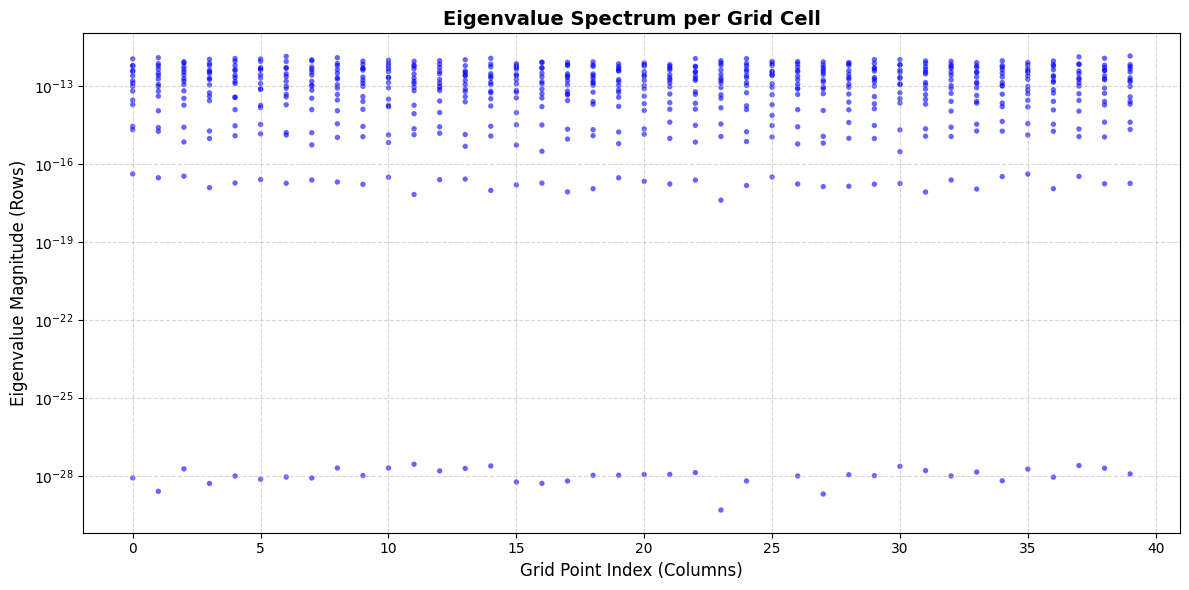

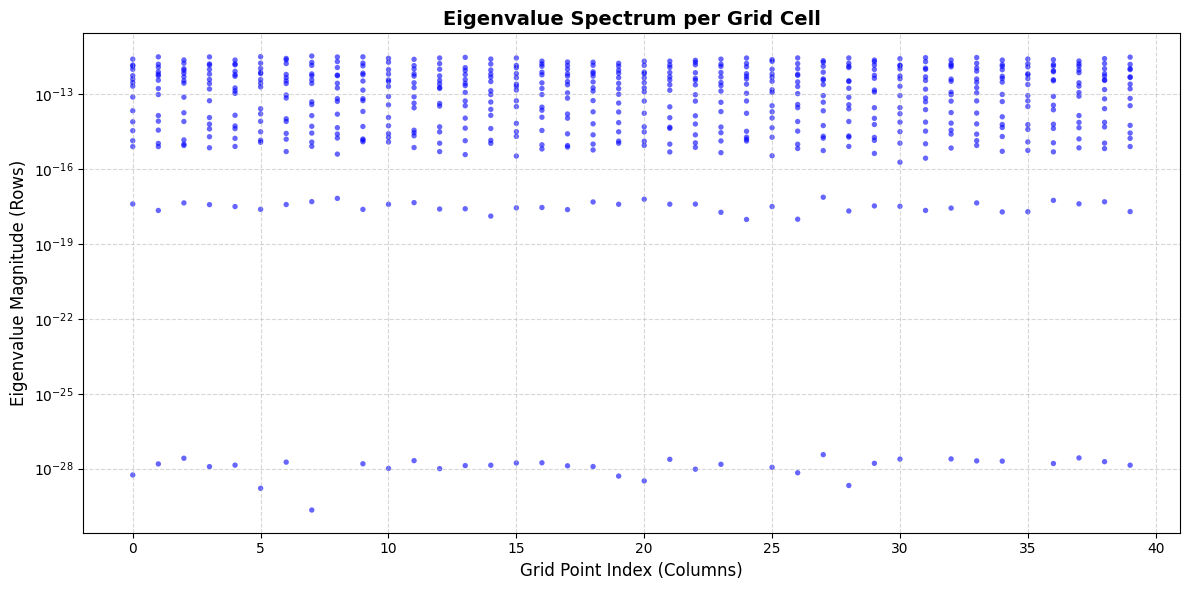

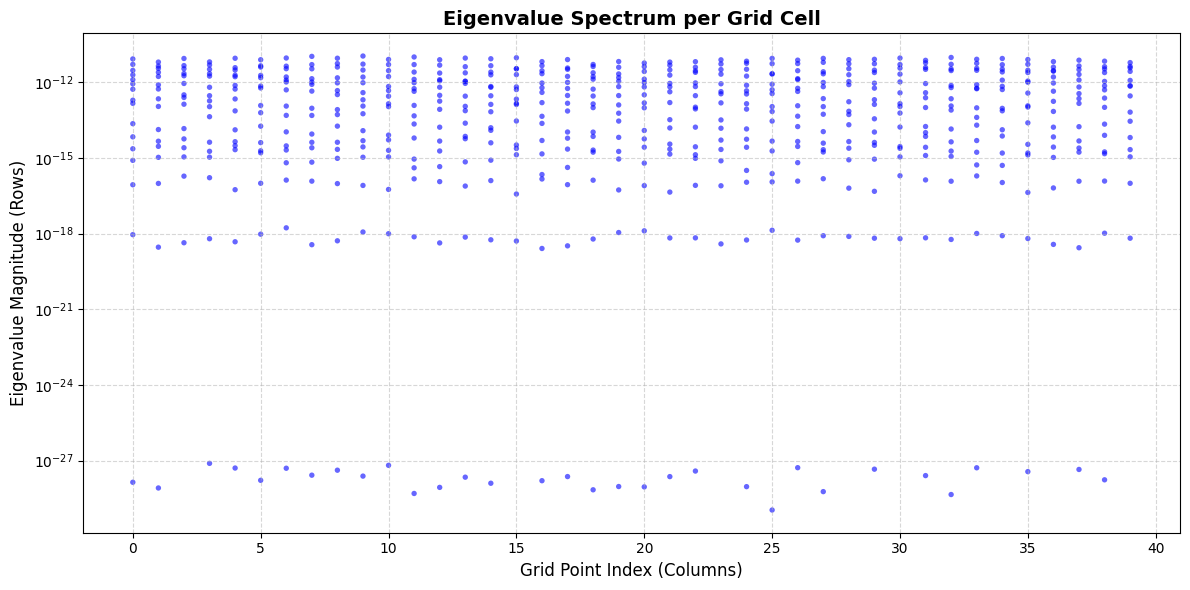

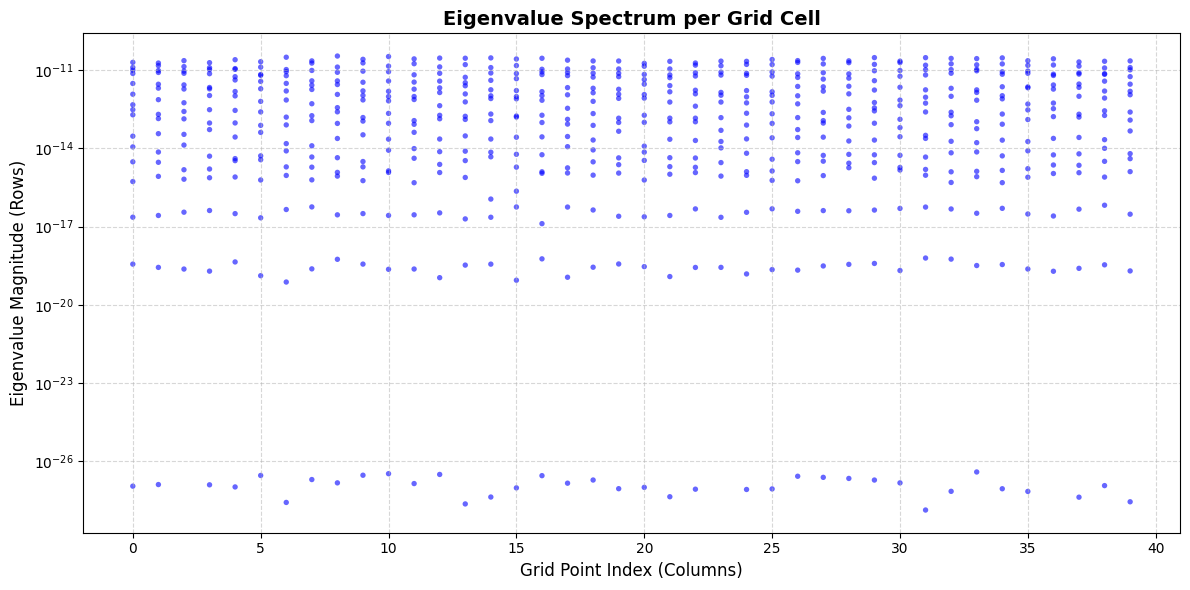

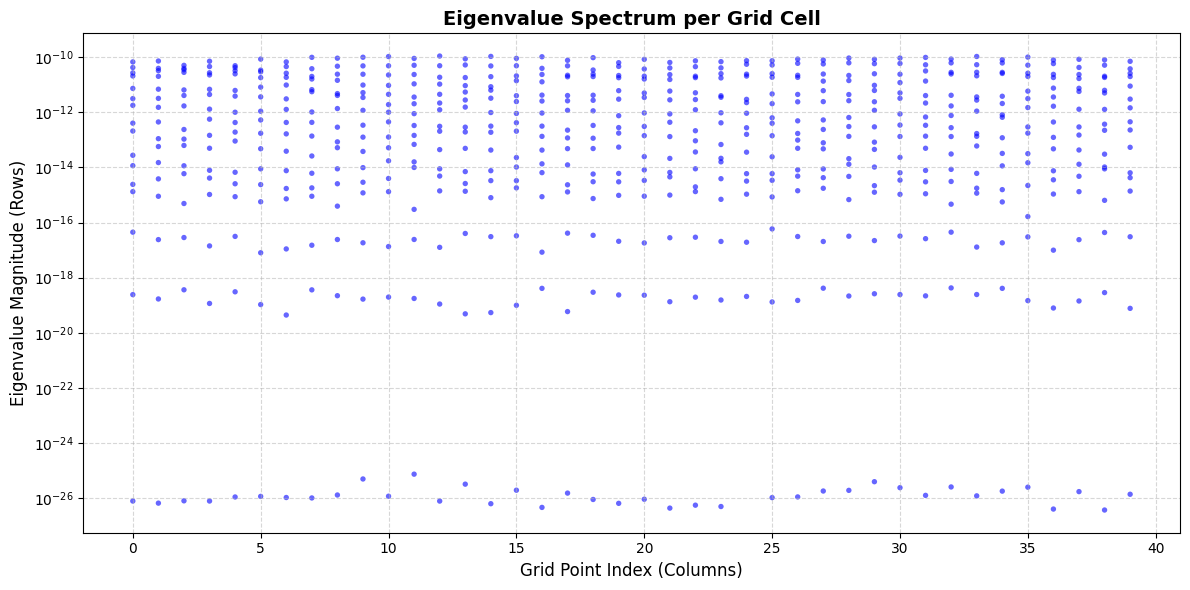

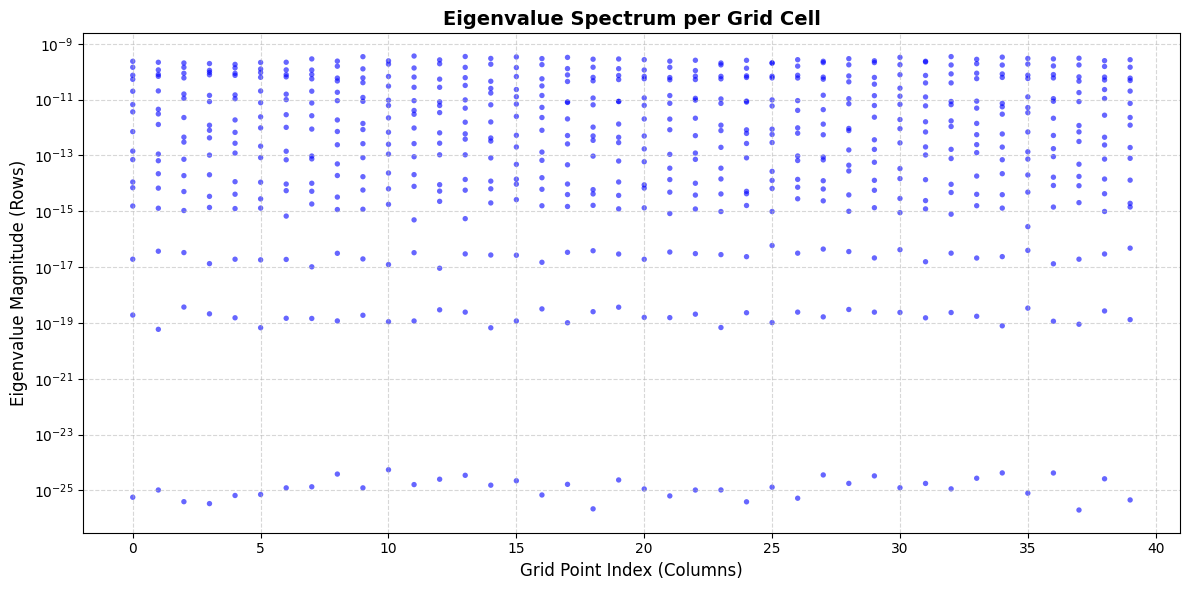

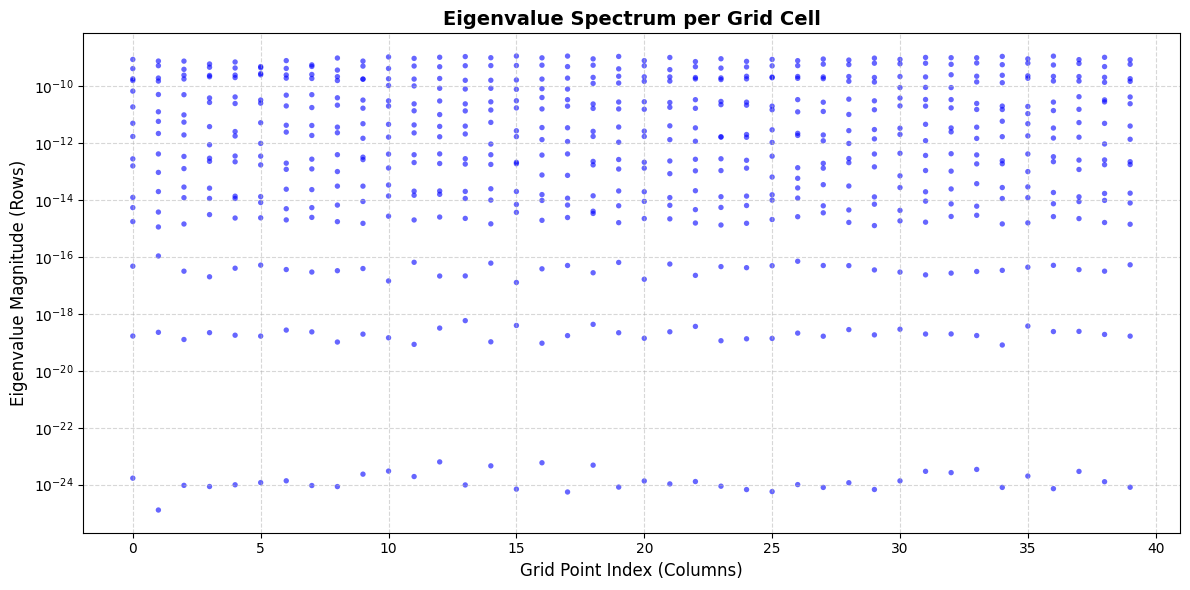

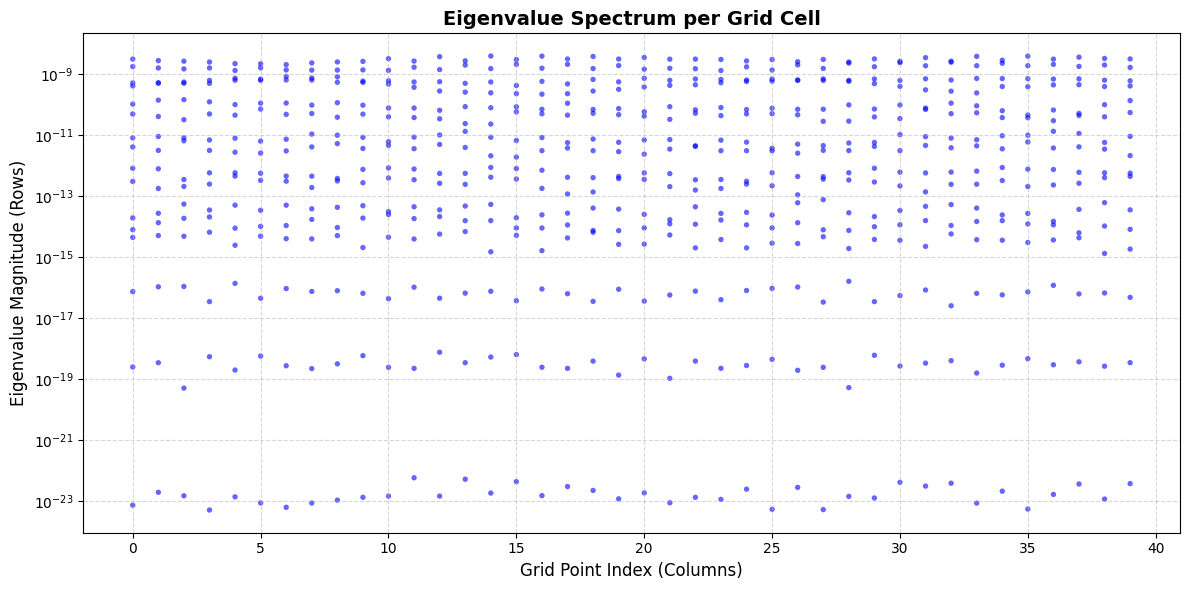

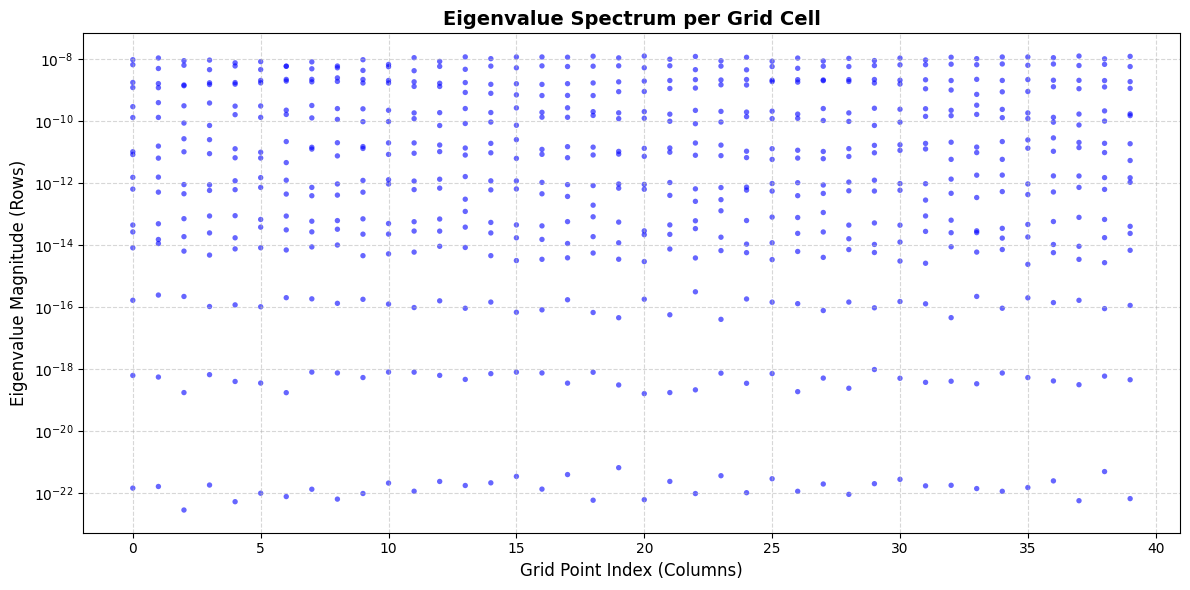

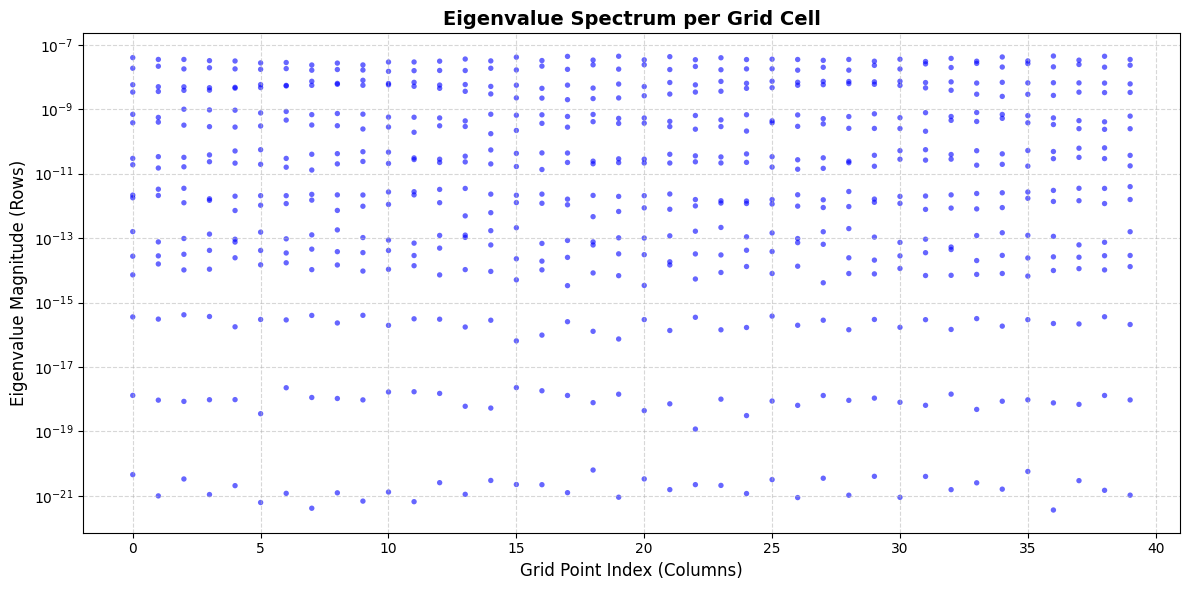

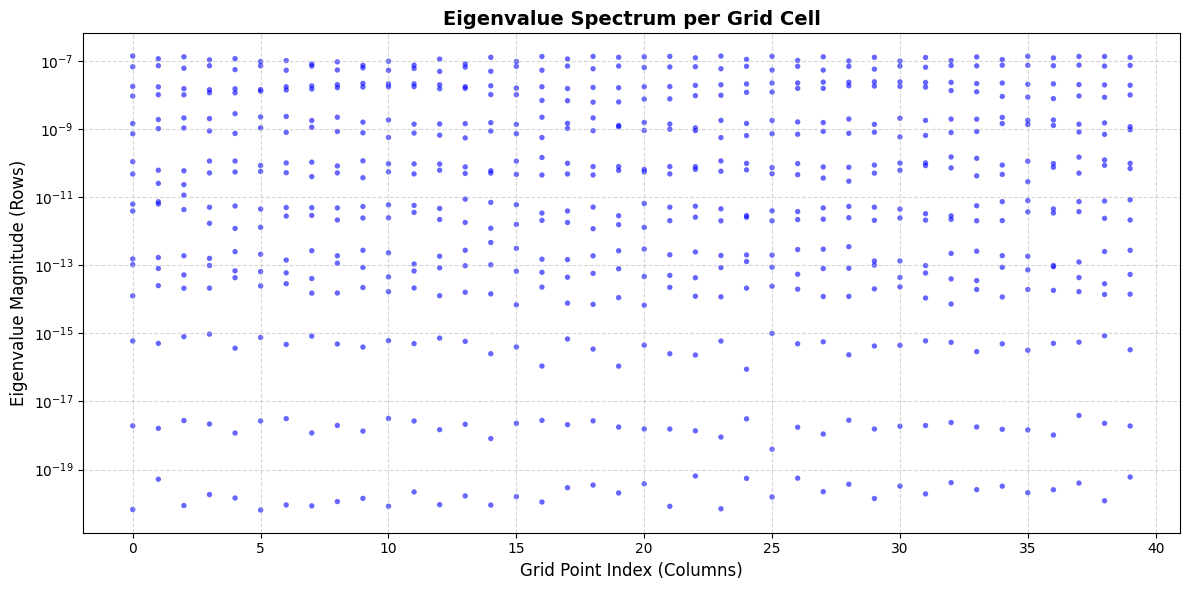

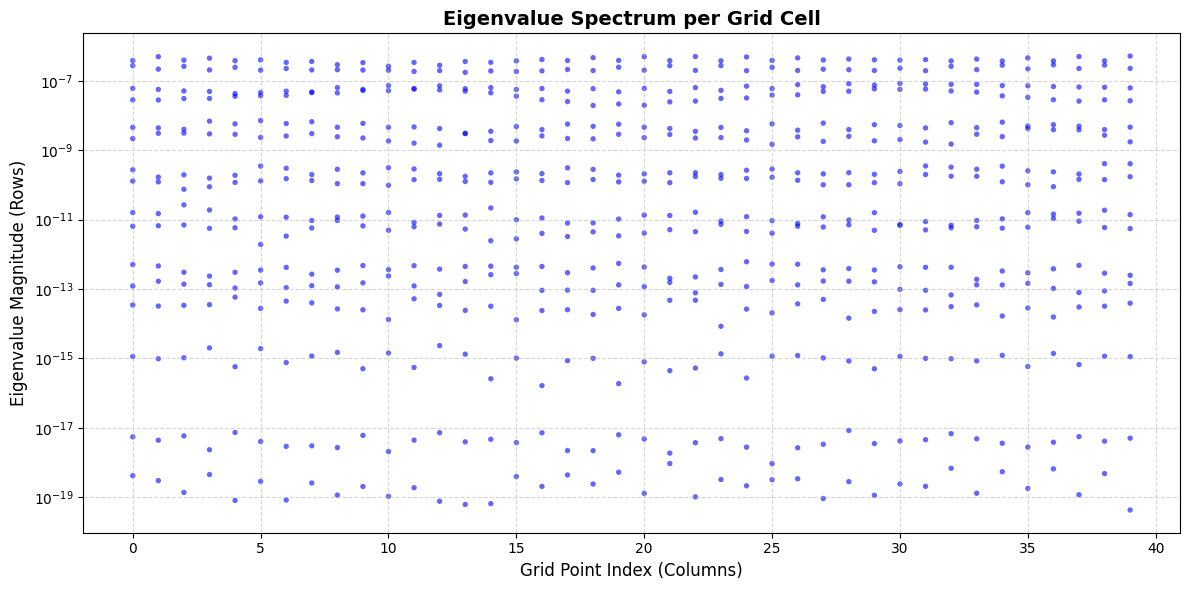

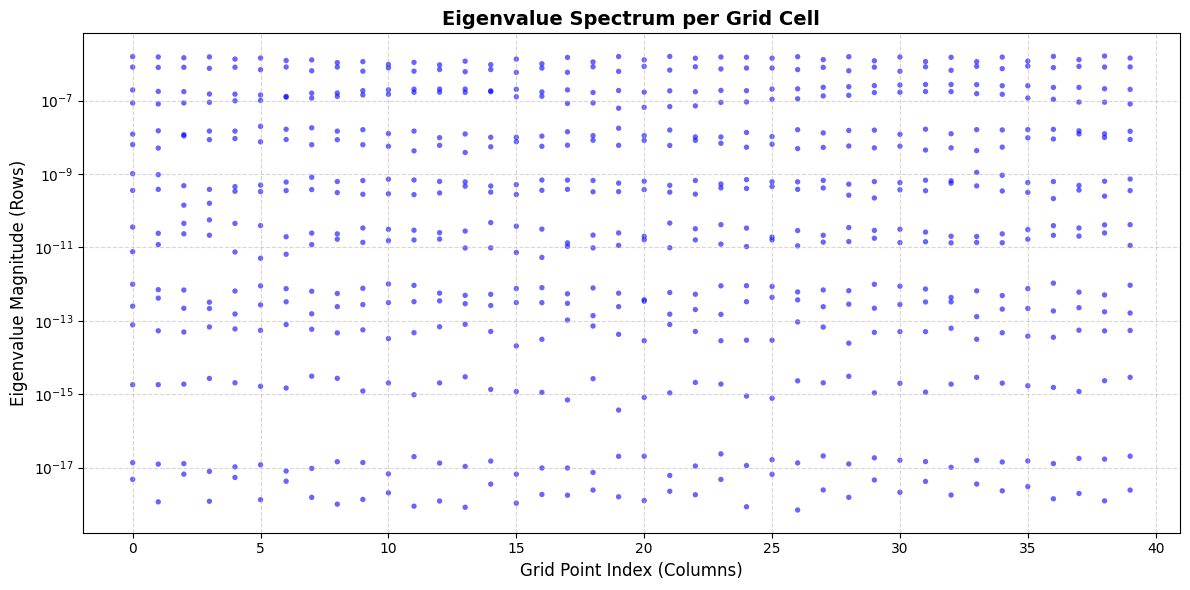

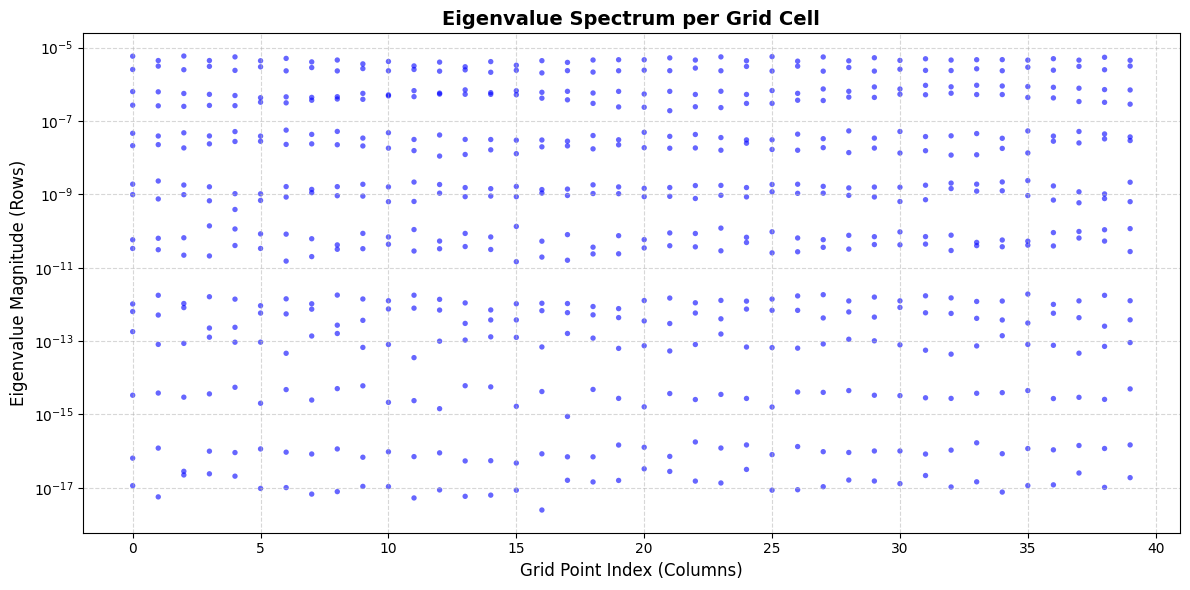

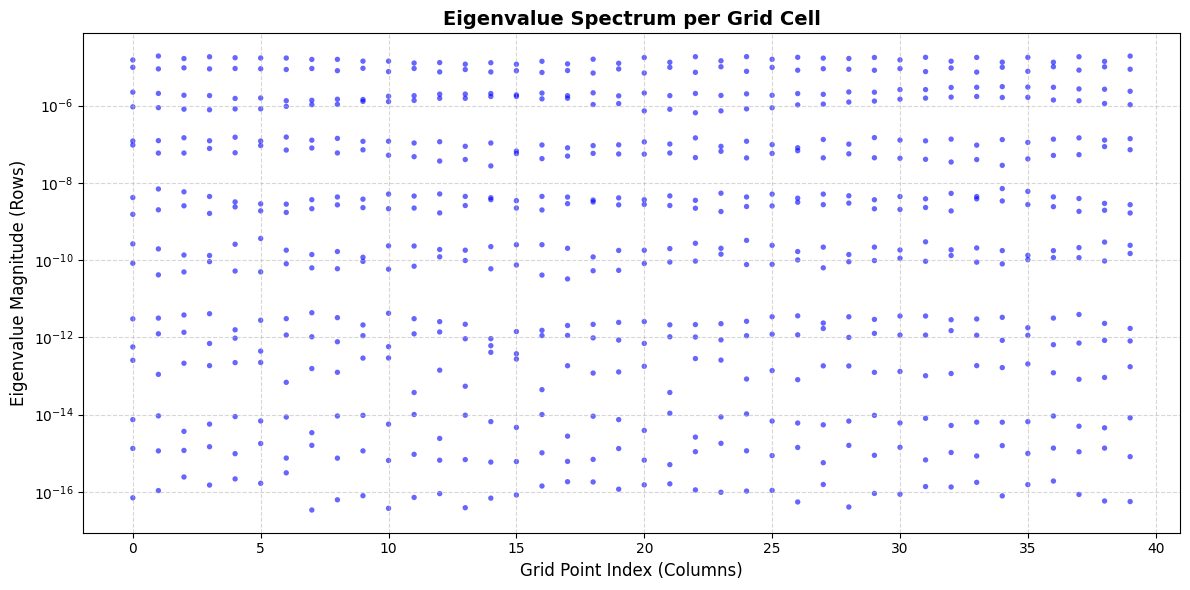

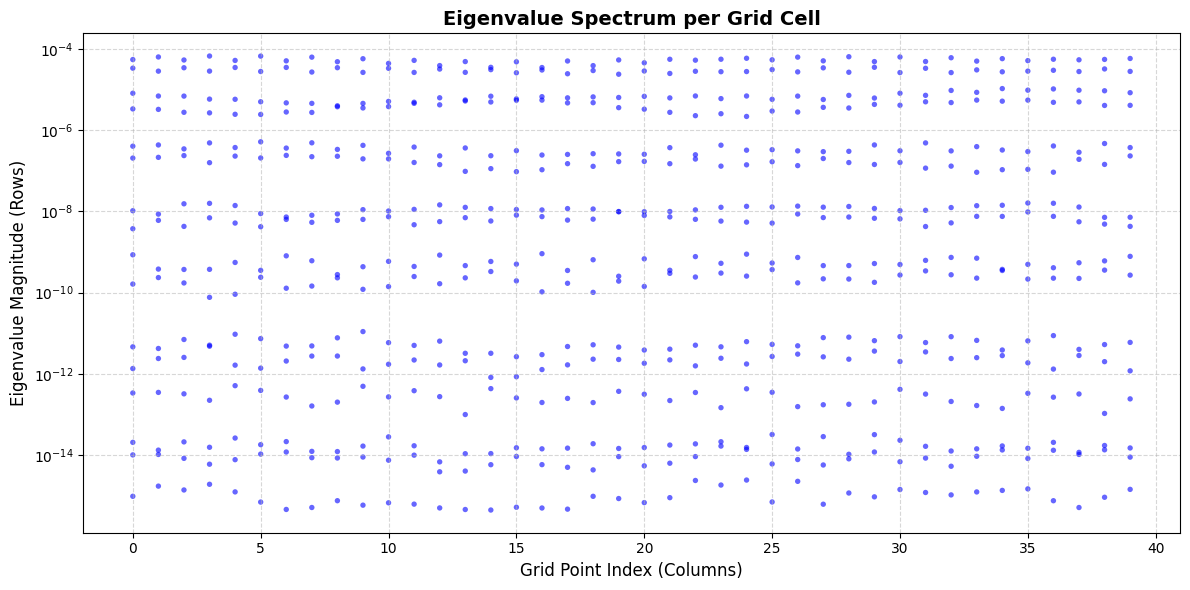

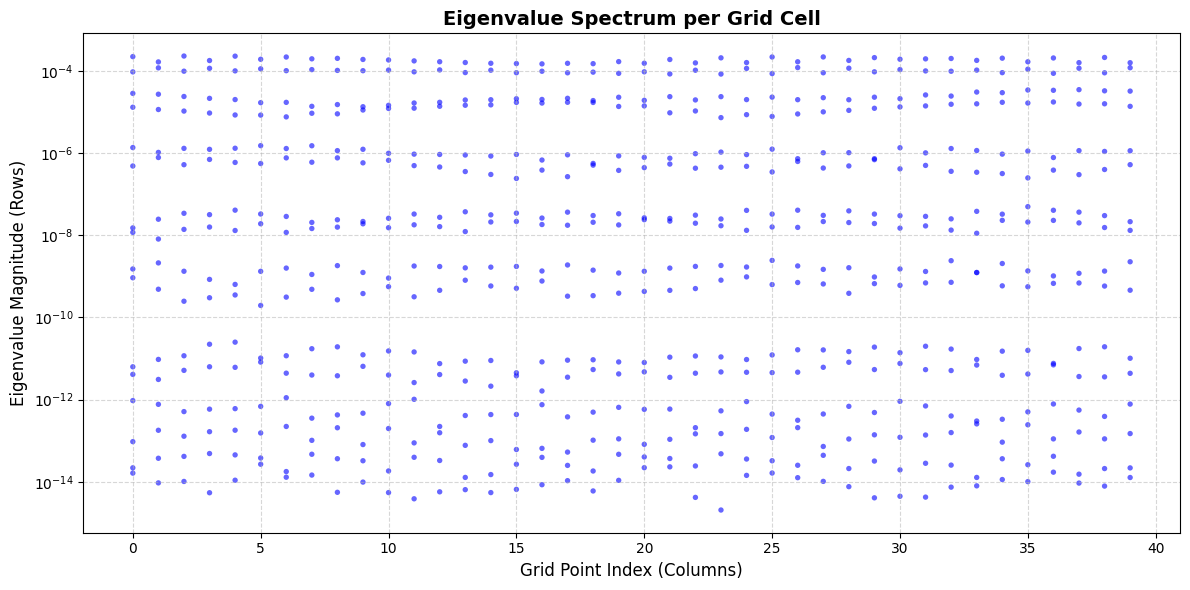

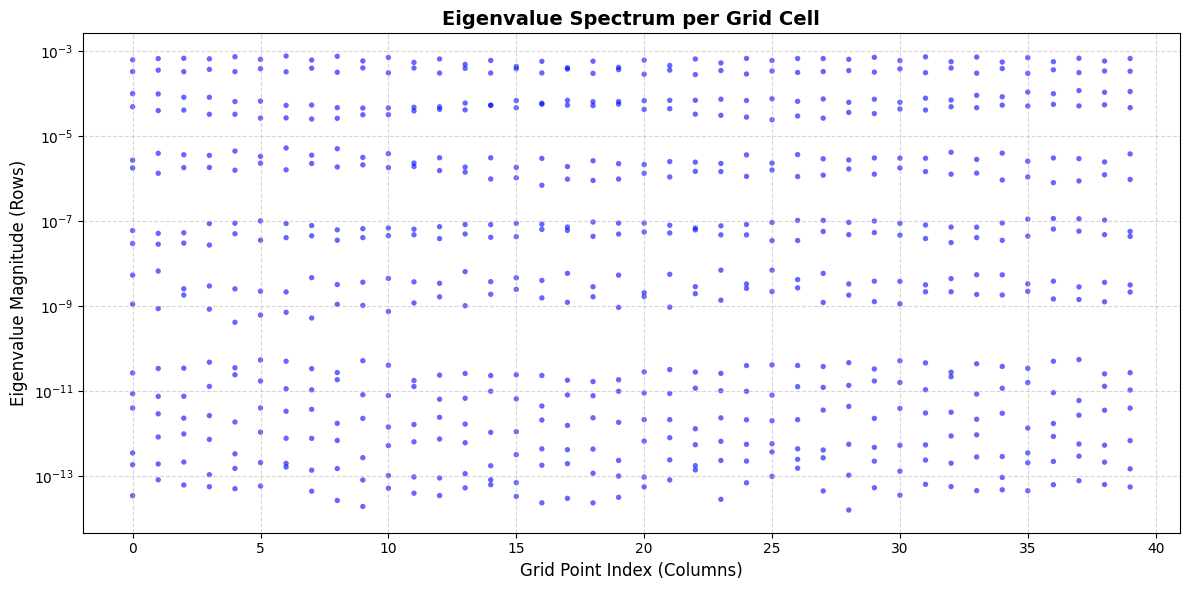

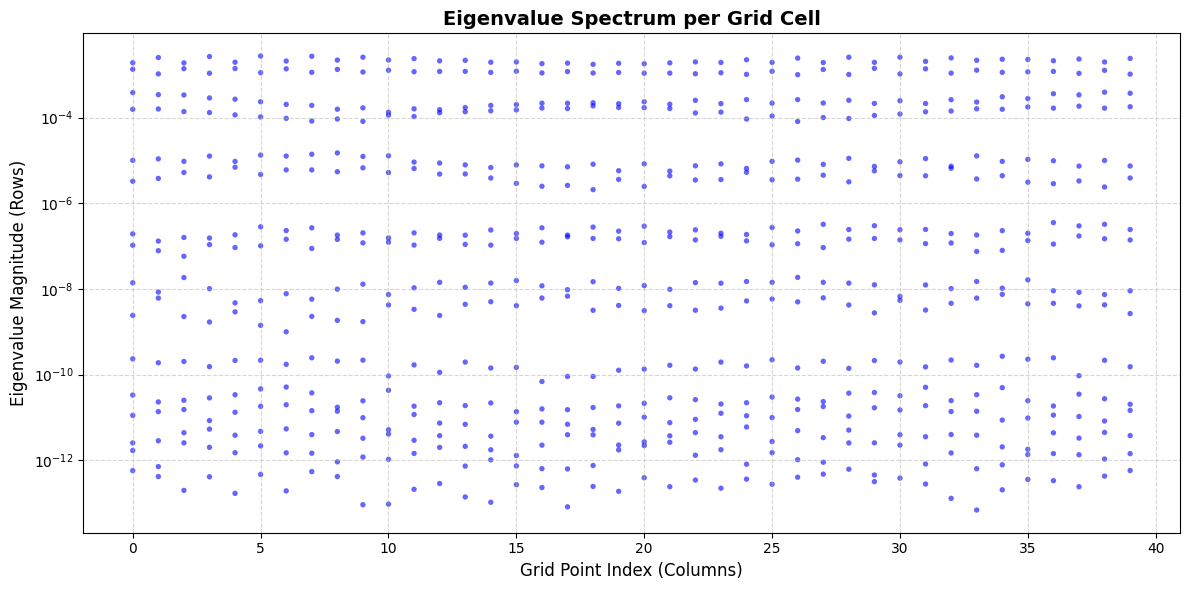

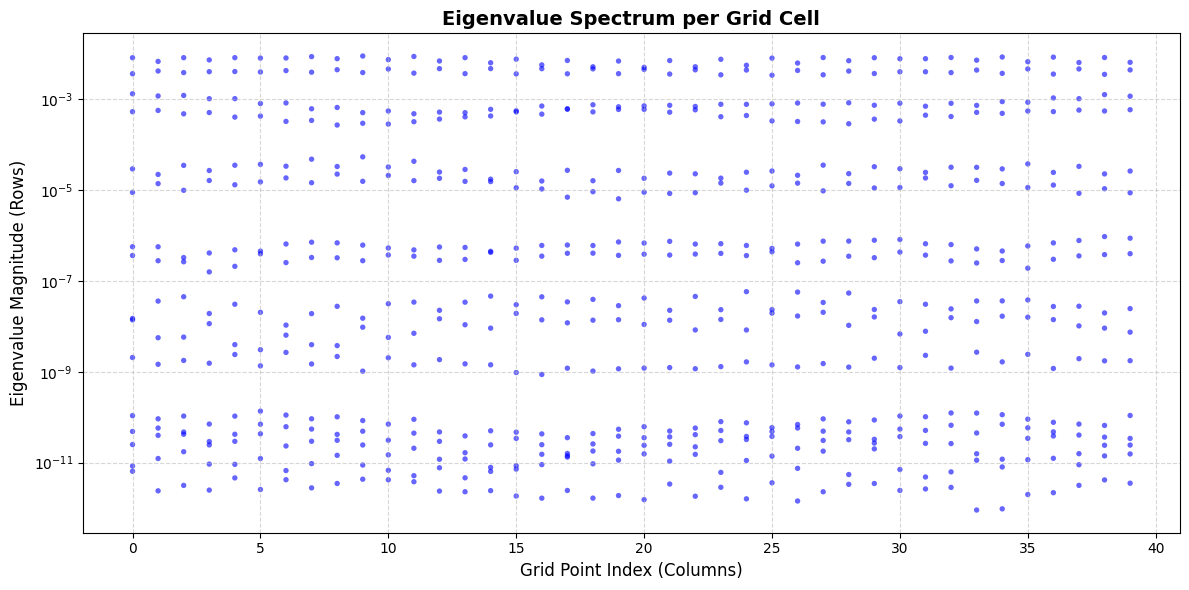

In [69]:
# Now that we have our ensembles generated we need to generate the LETLM, IETLM and GETLM for each time step
GETLMS = []
IETLMS = []
LETLMS = []

for i in range(len(Ensemble_final)-2):
    # We start by selecting the ensembles at each time level
    Chi = Ensemble_final[i+2]  # Future step matrix (N, ensemble_size)
    Xi  = Ensemble_final[i+1]  # Current step matrix (N, ensemble_size)
    X   = Ensemble_final[i]
    k = 2 # number of zero eigenvalue eigenvalues

    # We now make the GETLM
    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k, plot = True)
    GETLMS.append([N_tilde_G, L_tilde_G, K_tilde_G])

    # We will now make the IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_STENCIL_LARGE, model_parameters, ensemble_size_CN)
    IETLM_temp = torch.pinverse(N_tilde_I) @ L_tilde_I
    IETLMS.append(IETLM_temp)

    # We will now make the LETLM
    M_tilde = LETLMC.LETLM_generator(Chi, Xi, LETLM_STENCIL_LARGE, model_parameters, ensemble_size_CN)
    LETLMS.append(M_tilde)


tensor(0.)


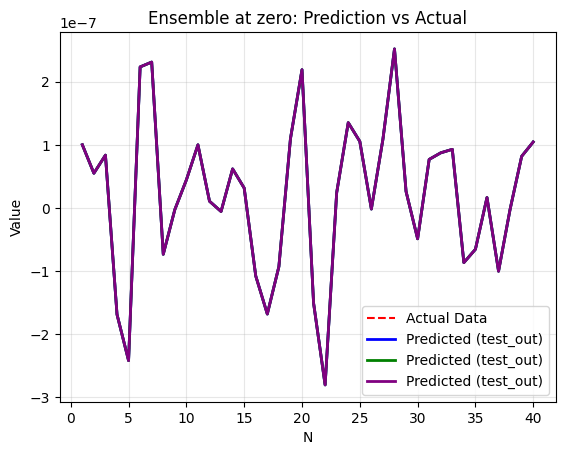

tensor(0.0141)
TLM Test GETLM: tensor(1.4289e-05)
TLM Test IETLM: tensor(1.9938e-15)
TLM Test LETLM: tensor(0.0141)


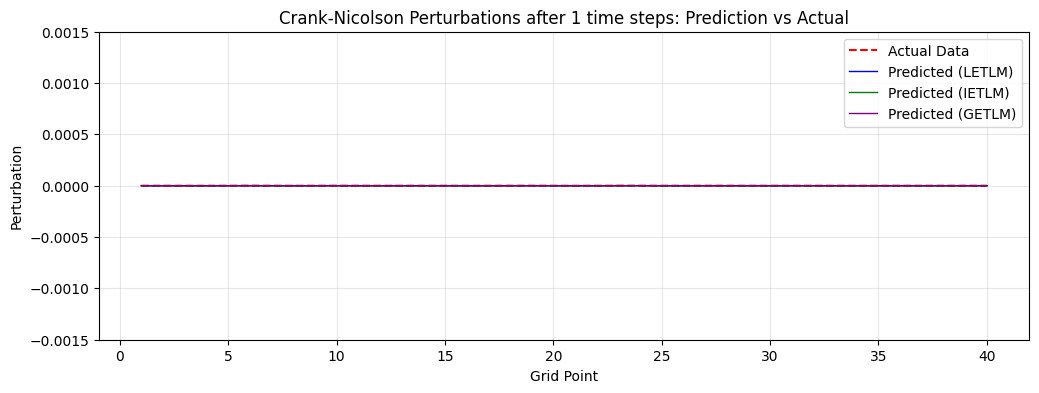

tensor(0.0232)
TLM Test GETLM: tensor(8.2318e-06)
TLM Test IETLM: tensor(1.8835e-15)
TLM Test LETLM: tensor(0.0232)


<Figure size 640x480 with 0 Axes>

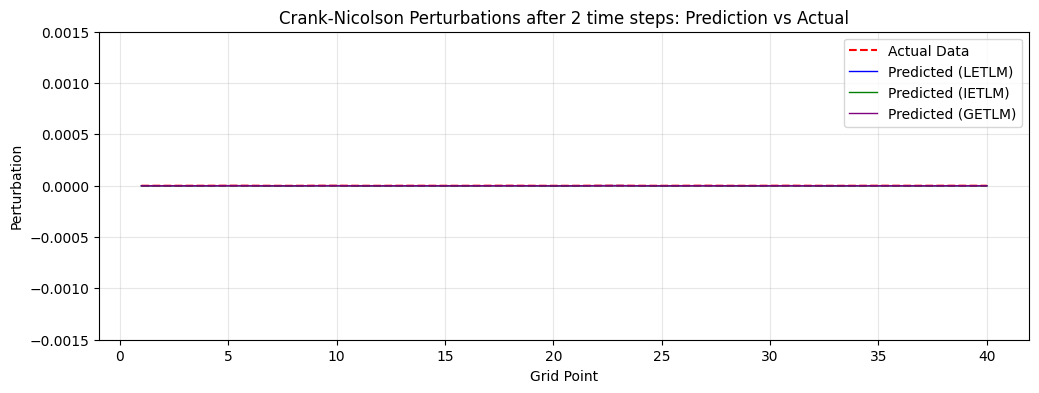

tensor(0.0301)
TLM Test GETLM: tensor(6.0463e-06)
TLM Test IETLM: tensor(2.3587e-15)
TLM Test LETLM: tensor(0.0301)


<Figure size 640x480 with 0 Axes>

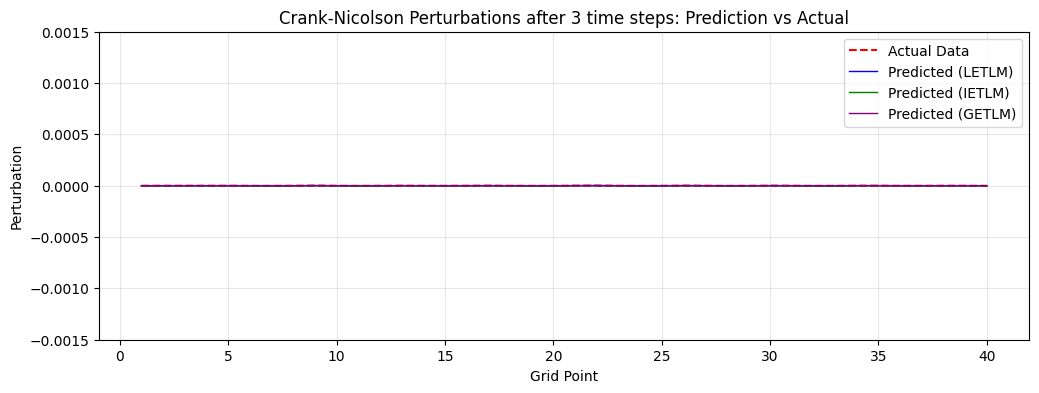

tensor(0.0344)
TLM Test GETLM: tensor(5.0817e-06)
TLM Test IETLM: tensor(1.4454e-14)
TLM Test LETLM: tensor(0.0344)


<Figure size 640x480 with 0 Axes>

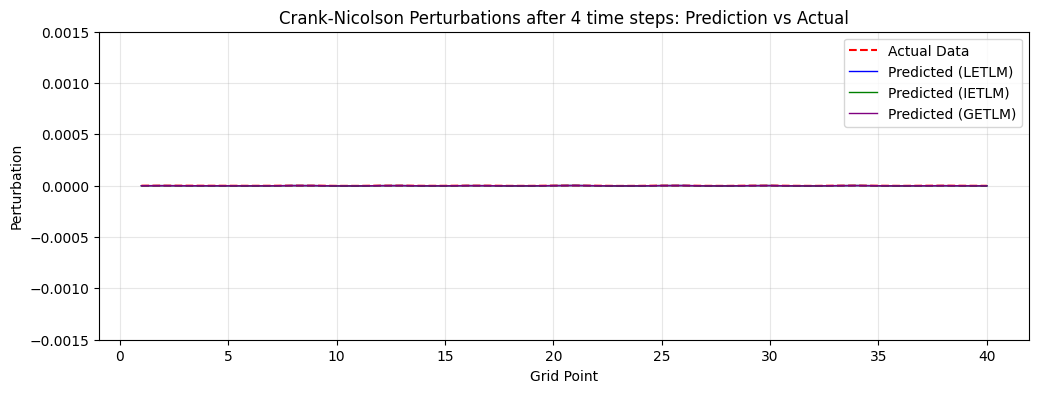

tensor(0.0378)
TLM Test GETLM: tensor(4.7261e-06)
TLM Test IETLM: tensor(6.9859e-14)
TLM Test LETLM: tensor(0.0378)


<Figure size 640x480 with 0 Axes>

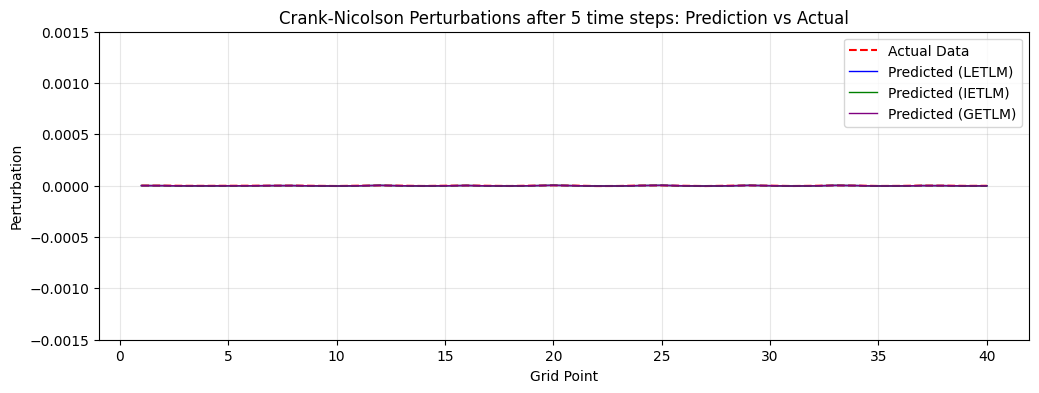

tensor(0.0443)
TLM Test GETLM: tensor(4.5837e-06)
TLM Test IETLM: tensor(2.9215e-13)
TLM Test LETLM: tensor(0.0443)


<Figure size 640x480 with 0 Axes>

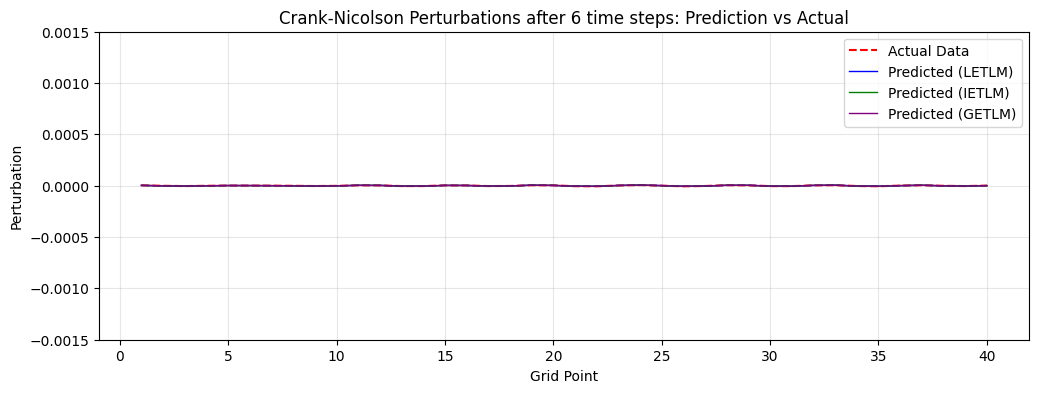

tensor(0.0734)
TLM Test GETLM: tensor(4.5364e-06)
TLM Test IETLM: tensor(1.0738e-12)
TLM Test LETLM: tensor(0.0734)


<Figure size 640x480 with 0 Axes>

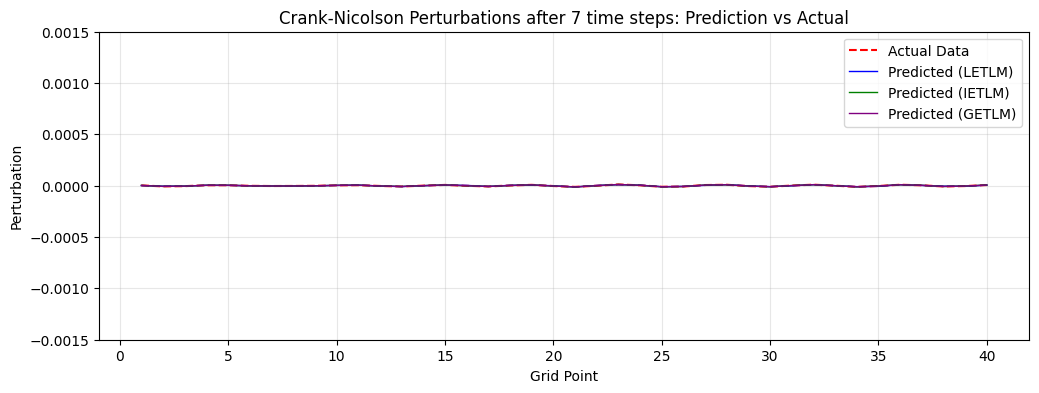

tensor(0.2105)
TLM Test GETLM: tensor(4.5060e-06)
TLM Test IETLM: tensor(4.0378e-12)
TLM Test LETLM: tensor(0.2105)


<Figure size 640x480 with 0 Axes>

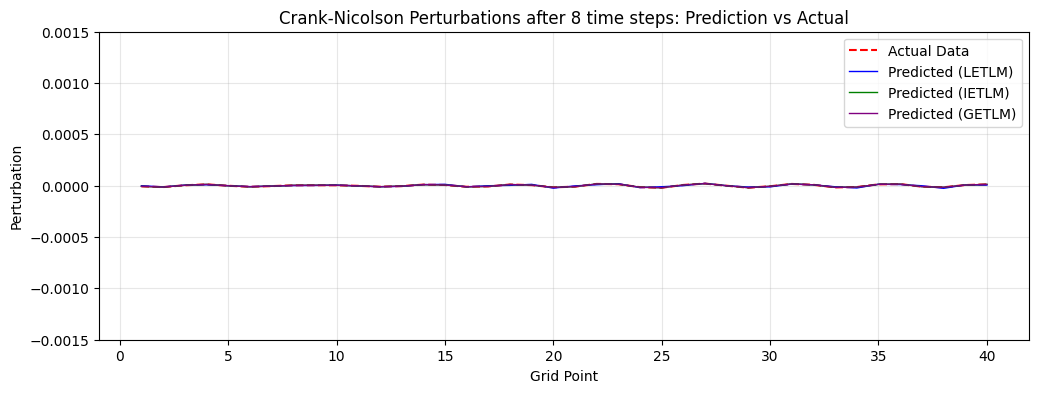

tensor(0.8329)
TLM Test GETLM: tensor(4.4938e-06)
TLM Test IETLM: tensor(1.3190e-11)
TLM Test LETLM: tensor(0.8329)


<Figure size 640x480 with 0 Axes>

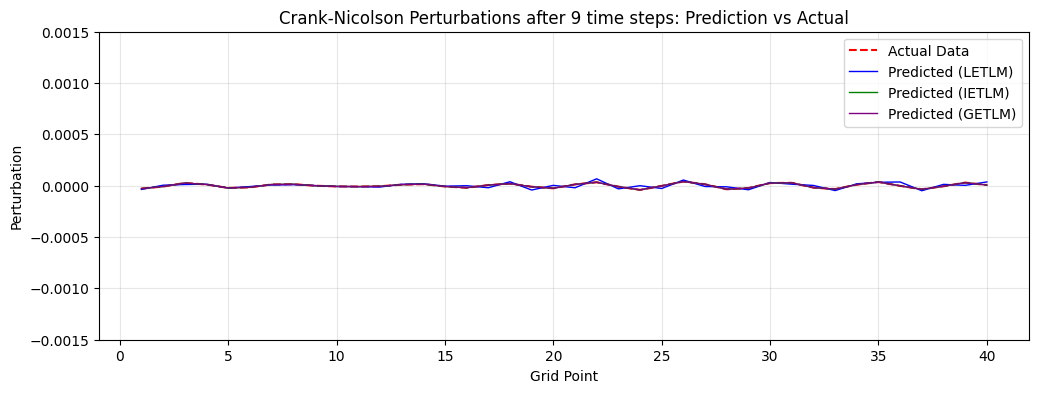

tensor(4.7628)
TLM Test GETLM: tensor(4.4875e-06)
TLM Test IETLM: tensor(4.6986e-11)
TLM Test LETLM: tensor(4.7628)


<Figure size 640x480 with 0 Axes>

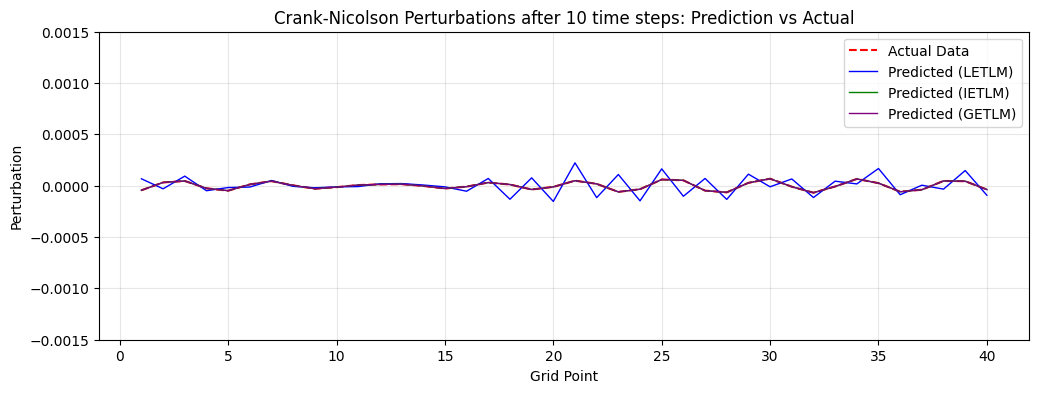

tensor(31.4313)
TLM Test GETLM: tensor(4.4855e-06)
TLM Test IETLM: tensor(1.4999e-10)
TLM Test LETLM: tensor(31.4313)


<Figure size 640x480 with 0 Axes>

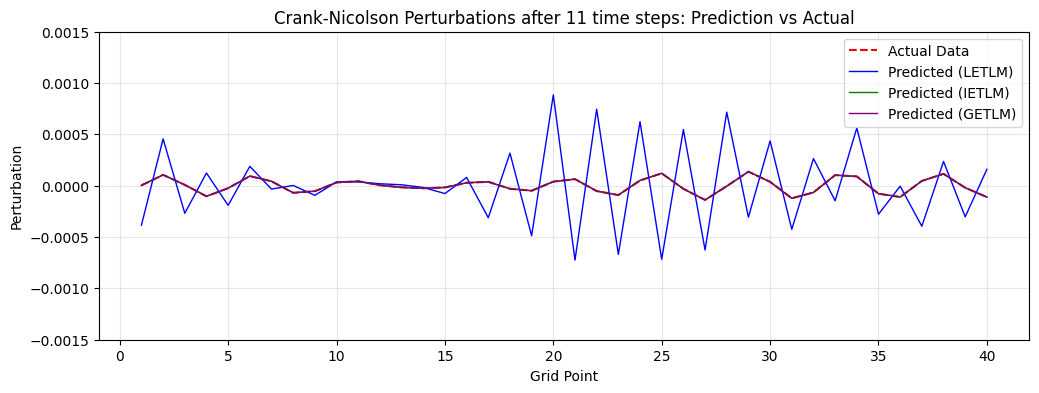

tensor(231.5846)
TLM Test GETLM: tensor(4.4861e-06)
TLM Test IETLM: tensor(5.3673e-10)
TLM Test LETLM: tensor(231.5846)


<Figure size 640x480 with 0 Axes>

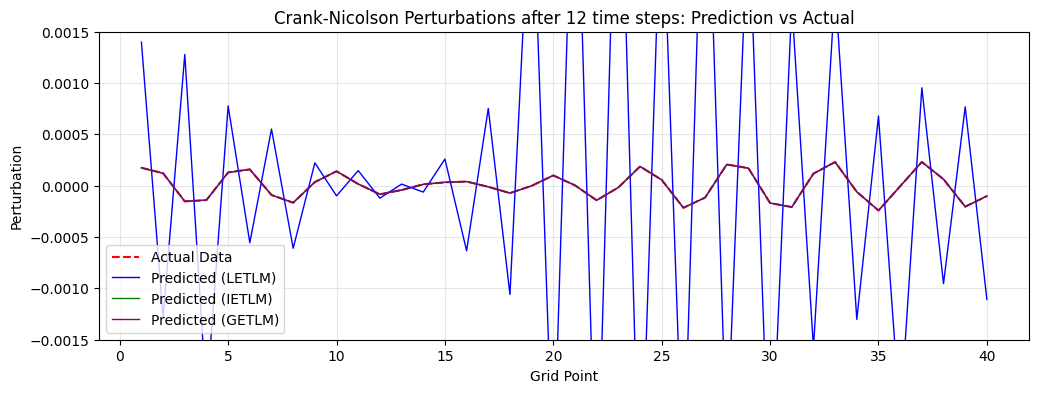

tensor(1857.0964)
TLM Test GETLM: tensor(4.4755e-06)
TLM Test IETLM: tensor(1.7324e-09)
TLM Test LETLM: tensor(1857.0964)


<Figure size 640x480 with 0 Axes>

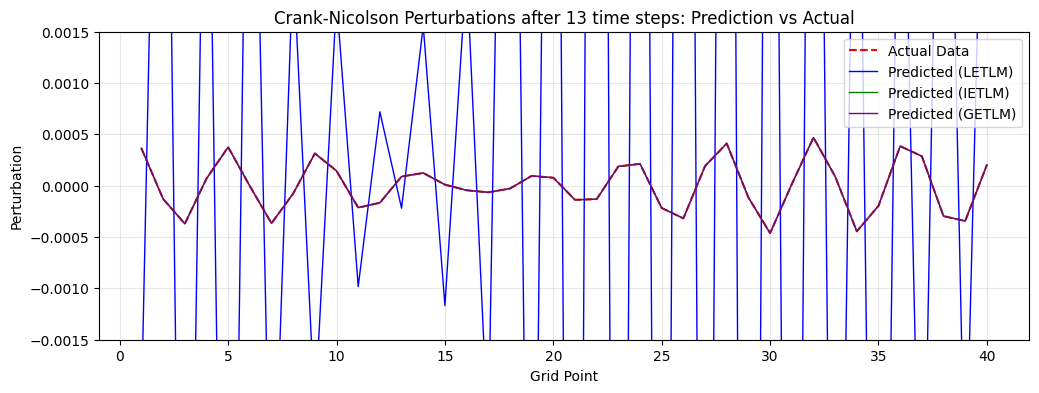

tensor(15276.9591)
TLM Test GETLM: tensor(4.4699e-06)
TLM Test IETLM: tensor(6.0246e-09)
TLM Test LETLM: tensor(15276.9591)


<Figure size 640x480 with 0 Axes>

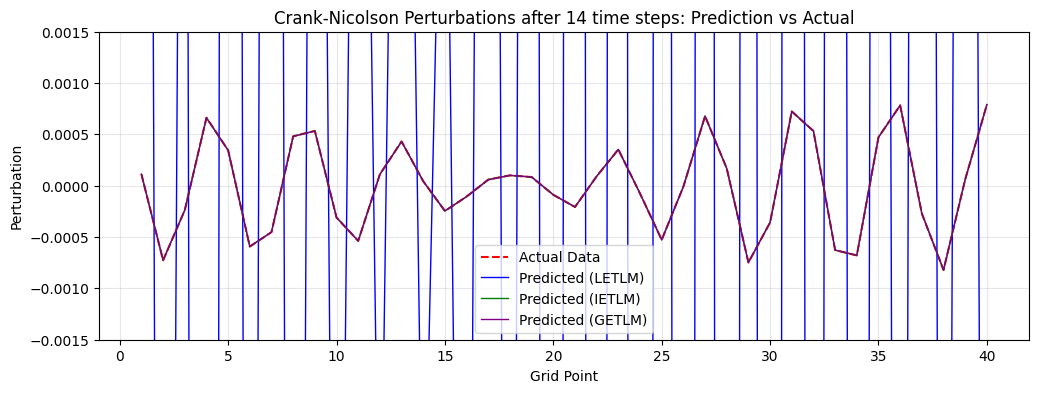

tensor(132441.3169)
TLM Test GETLM: tensor(4.4509e-06)
TLM Test IETLM: tensor(1.9731e-08)
TLM Test LETLM: tensor(132441.3169)


<Figure size 640x480 with 0 Axes>

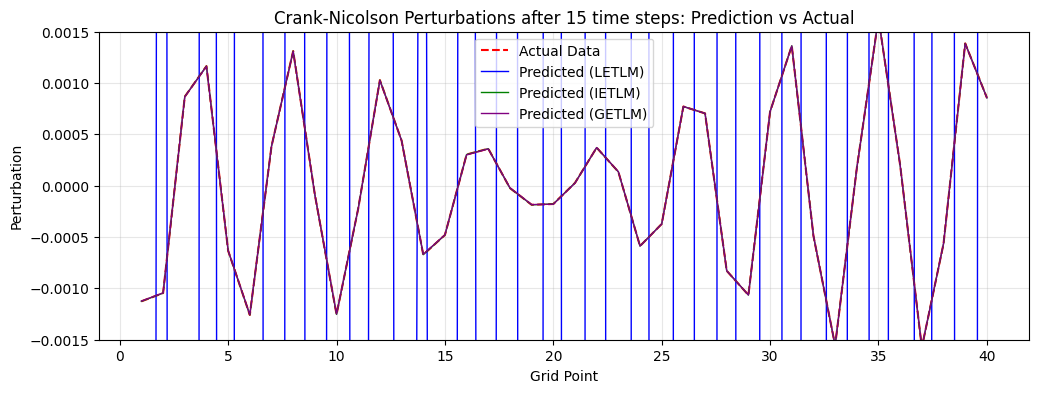

tensor(1146304.8834)
TLM Test GETLM: tensor(4.4869e-06)
TLM Test IETLM: tensor(6.7649e-08)
TLM Test LETLM: tensor(1146304.8834)


<Figure size 640x480 with 0 Axes>

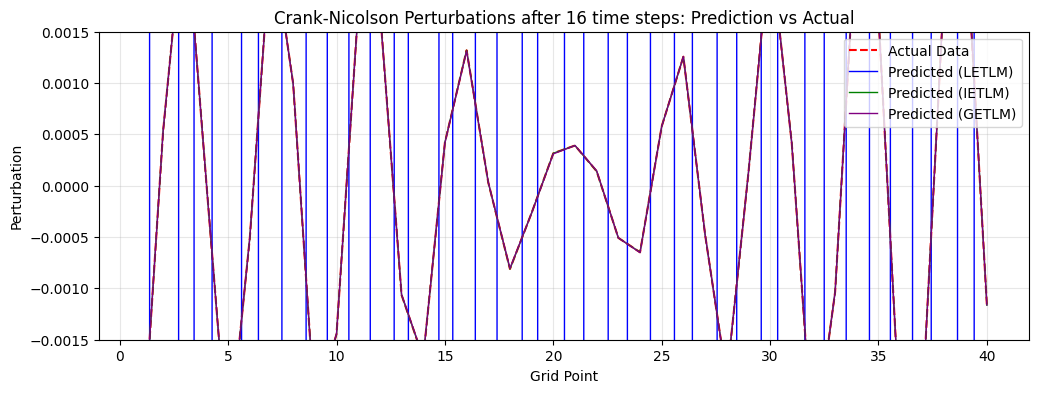

tensor(10315726.4025)
TLM Test GETLM: tensor(4.7808e-06)
TLM Test IETLM: tensor(2.2213e-07)
TLM Test LETLM: tensor(10315726.4025)


<Figure size 640x480 with 0 Axes>

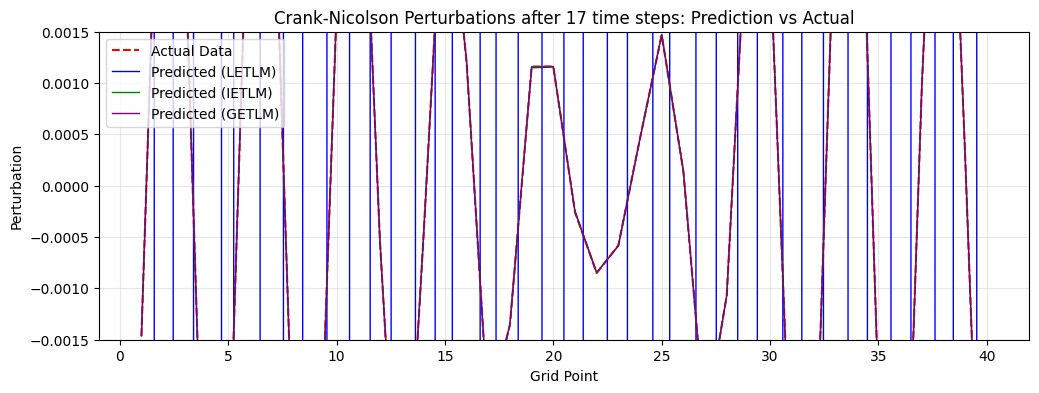

tensor(97103077.2631)
TLM Test GETLM: tensor(5.7826e-06)
TLM Test IETLM: tensor(7.6916e-07)
TLM Test LETLM: tensor(97103077.2631)


<Figure size 640x480 with 0 Axes>

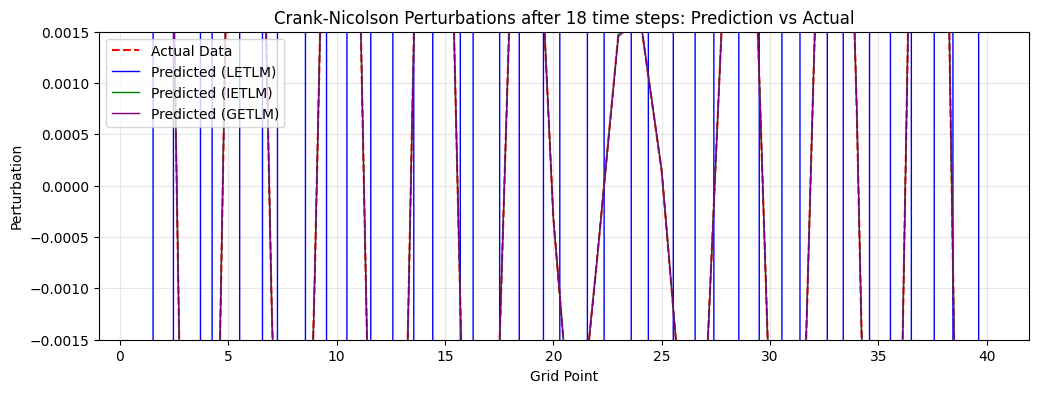

tensor(9.2328e+08)
TLM Test GETLM: tensor(9.3650e-06)
TLM Test IETLM: tensor(2.5715e-06)
TLM Test LETLM: tensor(9.2328e+08)


<Figure size 640x480 with 0 Axes>

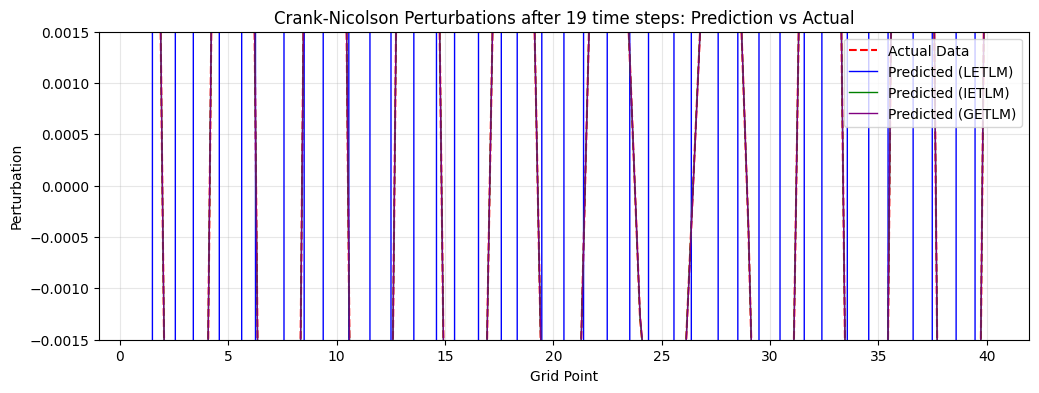

<Figure size 640x480 with 0 Axes>

In [70]:
# We will now compare the TLMS to the actual data to see 

# We first set a starting point for the TLMS
starting_time = 1

x_values = np.arange(1, N + 1)

LETLM_norm= []
IETLM_norm = []
GETLM_norm = []


LETLM_TT_result = []
IETLM_TT_result = []
GETLM_TT_result = []


# The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
test_0 = test_final_pert[1+starting_time]
LETLM_test = test_0
IETLM_test = test_0
GETLM_test_future = test_0
GETLM_test_current = test_final_pert[starting_time]

letlm_norm = L2_norm(LETLM_test, test_0)
ietlm_norm = L2_norm(IETLM_test, test_0)
getlm_norm = L2_norm(GETLM_test_future, test_0)



LETLM_norm.append(letlm_norm)
IETLM_norm.append(ietlm_norm)
GETLM_norm.append(getlm_norm)

index = 1+starting_time

LETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
IETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )

print(LETLM_TT)
LETLM_TT_result.append(LETLM_TT)
IETLM_TT_result.append(IETLM_TT)
GETLM_TT_result.append(GETLM_TT)





plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='blue', linewidth=2)
plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)
plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

plt.title(f"Ensemble at zero: Prediction vs Actual")
plt.xlabel("N")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop

# We will now go through the steps to see how each of the TLMS goes 
for i in range(len(test_final_pert)-3):
    index = i+2 + starting_time
    test = test_final_pert[i+2 + starting_time]
    letlm = LETLMS[i+starting_time]
    # print(len(letlm))
    LETLM_test = letlm @ LETLM_test

    letlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], LETLM_test)
    print(letlm_tt)
    LETLM_TT_result.append(letlm_tt)
    # LETLM_TT = torch.cat((LETLM_TT, letlm_tt), dim = 0)


    # Ploting the IETLM
    ietlm = IETLMS[i+starting_time]
    IETLM_test = ietlm @ IETLM_test


    ietlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], IETLM_test)
    IETLM_TT_result.append(ietlm_tt)


    # IETLM_TT = torch.cat((IETLM_TT, ietlm_tt), dim = 0)



    GETLM_test_past = GETLM_test_current
    GETLM_test_current = GETLM_test_future

    NL = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][1]
    NK = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][2]
    GETLM_test_future = NL @ GETLM_test_current + NK @ GETLM_test_past

    getlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future)

    # GETLM_TT = torch.cat((GETLM_TT, getlm_tt), dim = 0)
    GETLM_TT_result.append(getlm_tt)
    print('TLM Test GETLM:', getlm_tt)
    print('TLM Test IETLM:', ietlm_tt)
    print('TLM Test LETLM:', letlm_tt)




    

    # We now need to calculate the L2 norm

    letlm_norm = L2_norm(LETLM_test, test)
    ietlm_norm = L2_norm(IETLM_test, test)
    getlm_norm = L2_norm(GETLM_test_future, test)
    # print('IETLM norm:', ietlm_norm)
    # print('LETLM norm:', letlm_norm)
    # print('GETLM norm:', getlm_norm)
    LETLM_norm.append(letlm_norm)
    IETLM_norm.append(ietlm_norm)
    GETLM_norm.append(getlm_norm)

    plt.figure(figsize=(12, 4))  # width=12 inches, height=4 inches

    plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
    plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (LETLM)', color='blue', linewidth=1)
    plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (GETLM)', color='purple', linewidth=1)
    plt.ylim(-0.0015, 0.0015)
    plt.title(f"Crank-Nicolson Perturbations after {i+1} time steps: Prediction vs Actual")

    plt.xlabel("Grid Point")
    plt.ylabel("Perturbation")
    plt.legend()

    plt.grid(True, alpha=0.3)
    plt.show() # This creates a fresh window/plot for each step in the loop
    plt.clf()
    

    
    # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    # plt.show()
    # plt.clf()



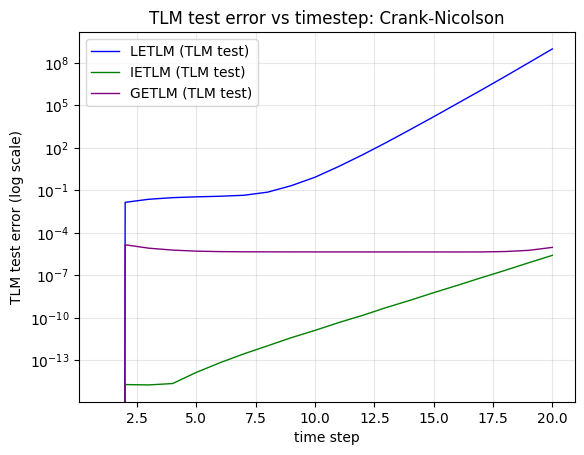

<Figure size 640x480 with 0 Axes>

In [71]:
x_values_norm = np.arange(1,len(IETLM_norm)+1)

plt.plot(x_values_norm, LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: Crank-Nicolson")
plt.xlabel("time step")
plt.ylabel("TLM test error (log scale)")
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


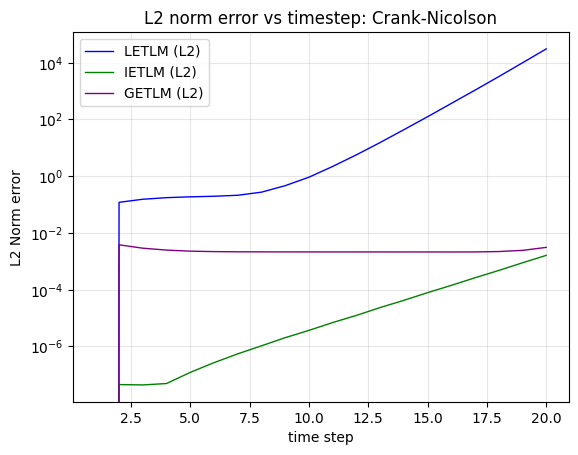

<Figure size 640x480 with 0 Axes>

In [72]:
x_values_norm = np.arange(1,len(IETLM_norm)+1)
plt.yscale('log')
plt.plot(x_values_norm, LETLM_norm, label='LETLM (L2)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_norm, label='IETLM (L2)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_norm, label='GETLM (L2)', color='purple', linewidth=1)


plt.title("L2 norm error vs timestep: Crank-Nicolson")
plt.xlabel("time step")
plt.ylabel("L2 Norm error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2946483006.py:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, LETLM_TT_result/IETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2946483006.py:6: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, IETLM_TT_result/IETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2946483006.py:7: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, GETLM_TT_result/IETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)


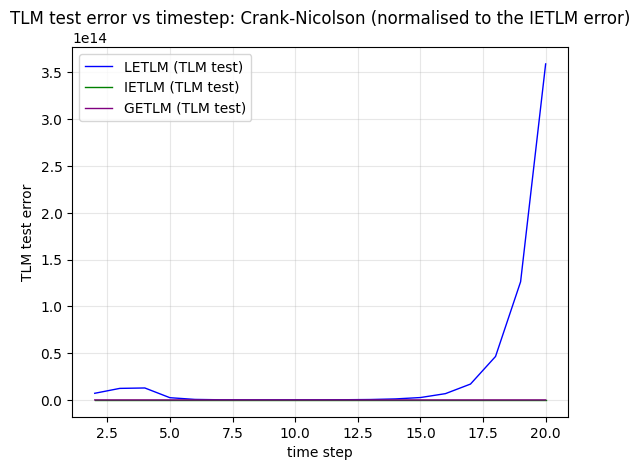

<Figure size 640x480 with 0 Axes>

In [73]:
LETLM_TT_result = np.array(LETLM_TT_result)
IETLM_TT_result = np.array(IETLM_TT_result)
GETLM_TT_result = np.array(GETLM_TT_result)

plt.plot(x_values_norm, LETLM_TT_result/IETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_TT_result/IETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_TT_result/IETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: Crank-Nicolson (normalised to the IETLM error)")
plt.xlabel("time step")
plt.ylabel("TLM test error")
# plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

In [74]:
# We will also repeat this for Runge-Kutta 4

# We will start by looking at Crank-Nicolson
# The first step is to the parameters for out model

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.05 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)
model = TST.rk4_L96
x_values = np.arange(1, N+1)  
spin_up_time = 1000

In [75]:
# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in tqdm(range(spin_up_time-1)):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)

100%|██████████| 999/999 [00:00<00:00, 16750.25it/s]


In [76]:
# Now that the model is spun up, we need to generate the ensembles

# The first step to do this is to work out what we want to use as our stencil
stencil_members_future_RK4 = [-2,-1,0,1]
stencil_members_current_RK4 = [-2,-1,0,1]
stencil_members_past_RK4 = [0]
stencil_members_large_RK4 = [stencil_members_future_RK4, stencil_members_current_RK4, stencil_members_past_RK4]

# Now that we have our stencil we can calculate how many ensemble members we need 
ensemble_size_RK4 = 9 + len(stencil_members_future_RK4) + len(stencil_members_current_RK4) + len(stencil_members_past_RK4)

# We now need to set the size of the perturbation that we will use for generating the ensemble TLMS
SD_pert = 10**(-7)

# We also need to define our test perturbation
Test_pert_current = torch.randn(N) * SD_pert
Test_pert_past = torch.randn(N) * SD_pert
Test_pert = (Test_pert_current, Test_pert_past)

test_final_pert, Ensemble_final, Ensembles, test_guess, unpert_run=  GETLMC.GETLM_ensemble_generator_mult(x_out, ensemble_size_RK4, SD_pert, model, model_parameters, Test_pert, number_of_steps = 20)


In [77]:
IETLM_STENCIL_LARGE_RK4 = [[-2,-1,0,1],[-2,-1,0,1]]
LETLM_STENCIL_LARGE_RK4 = [[0],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4]]

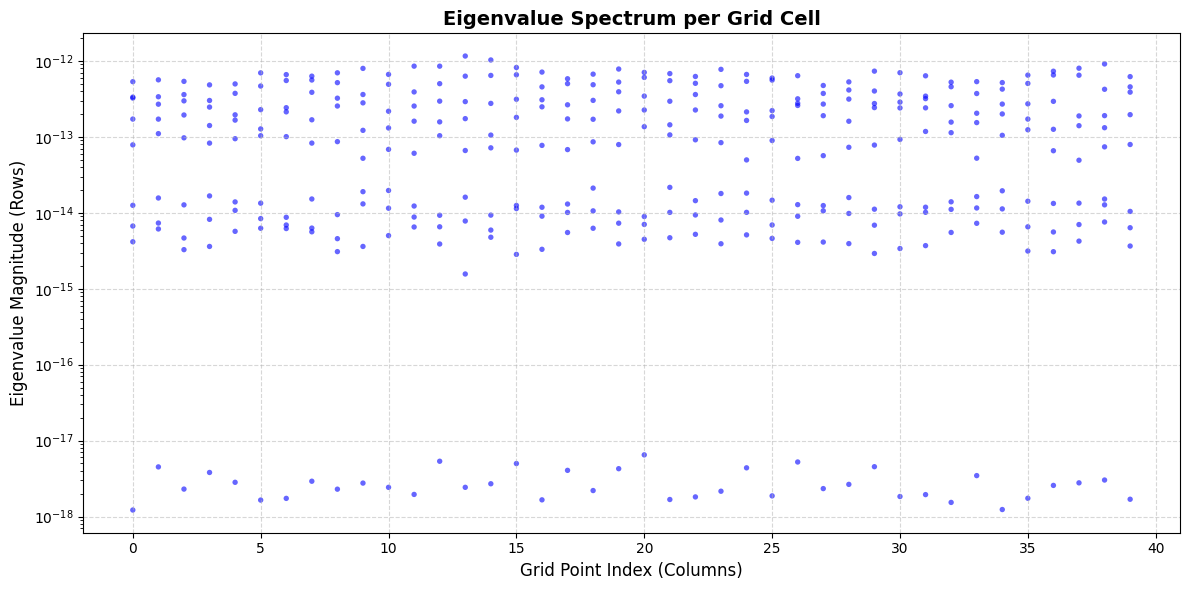

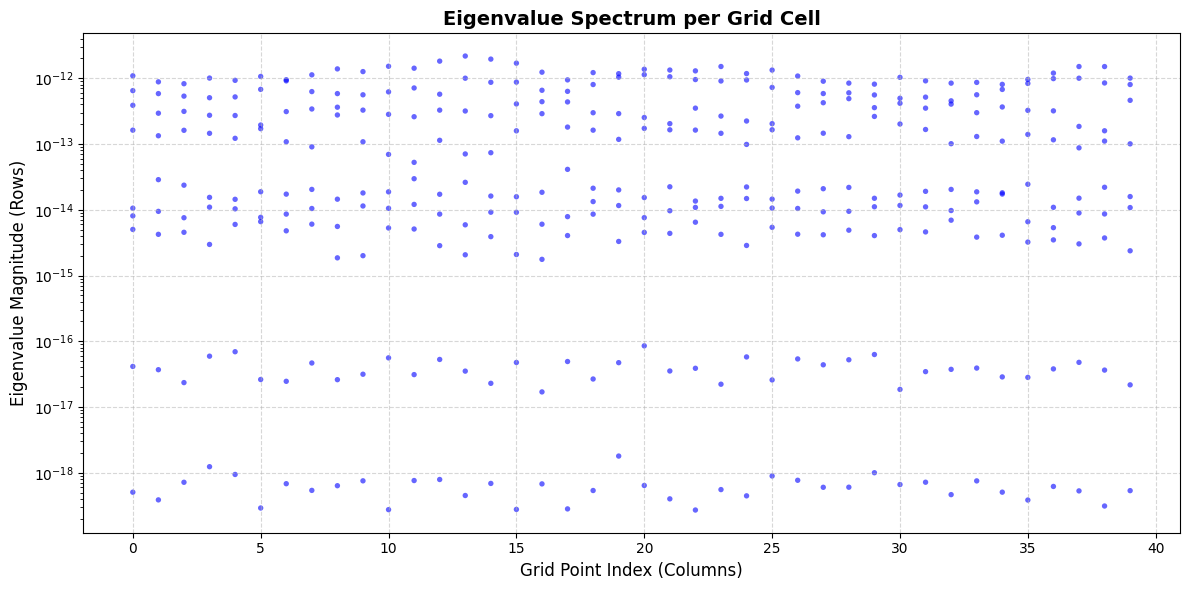

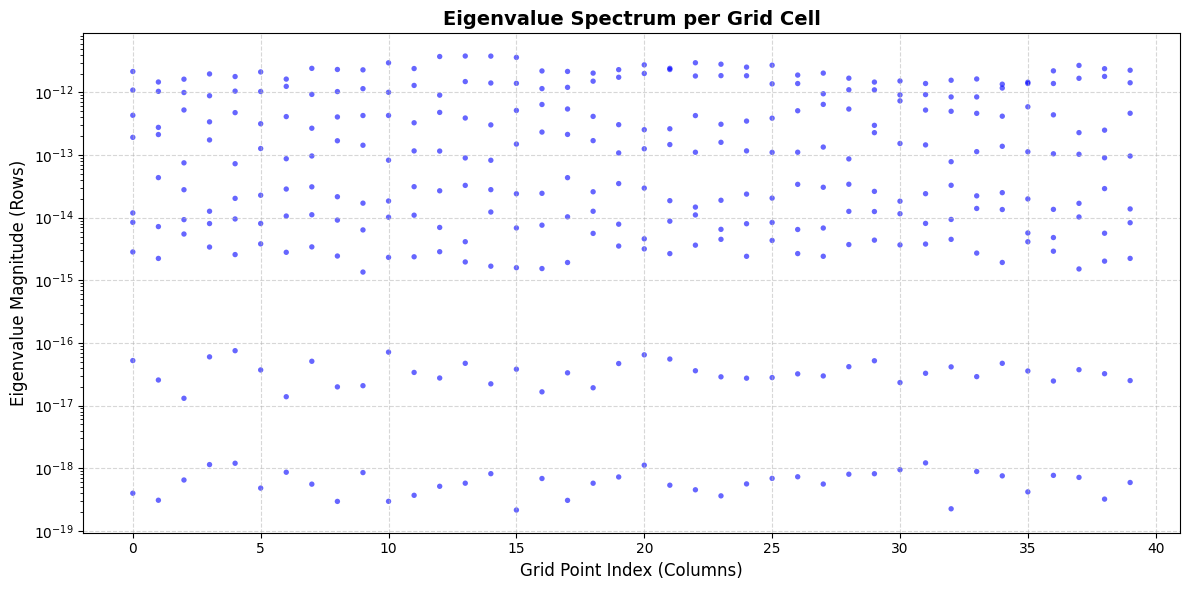

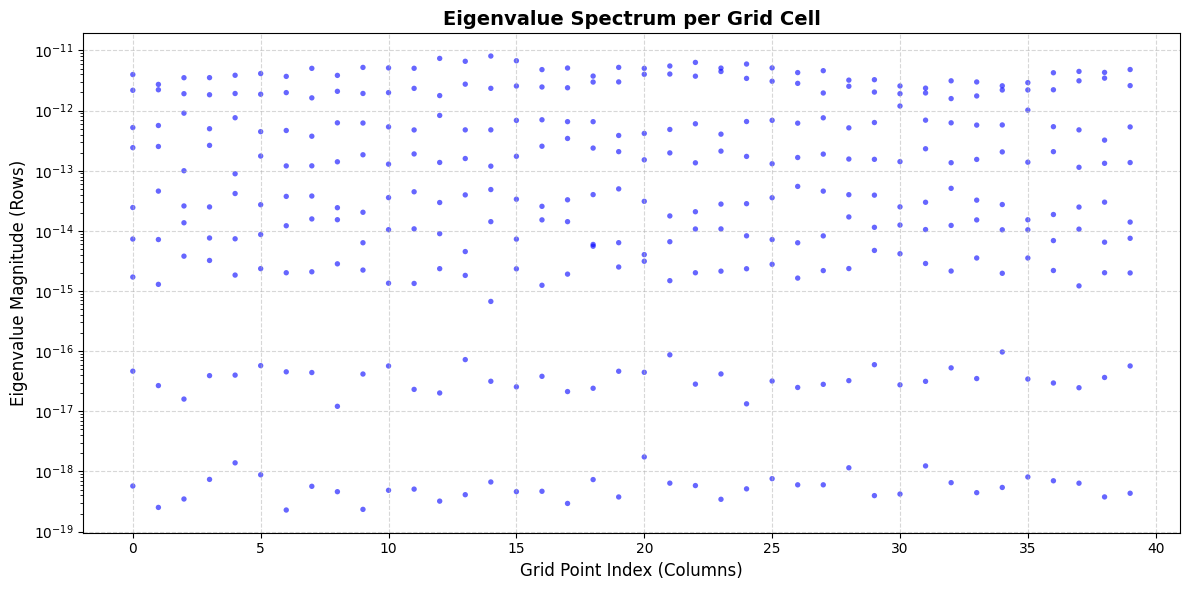

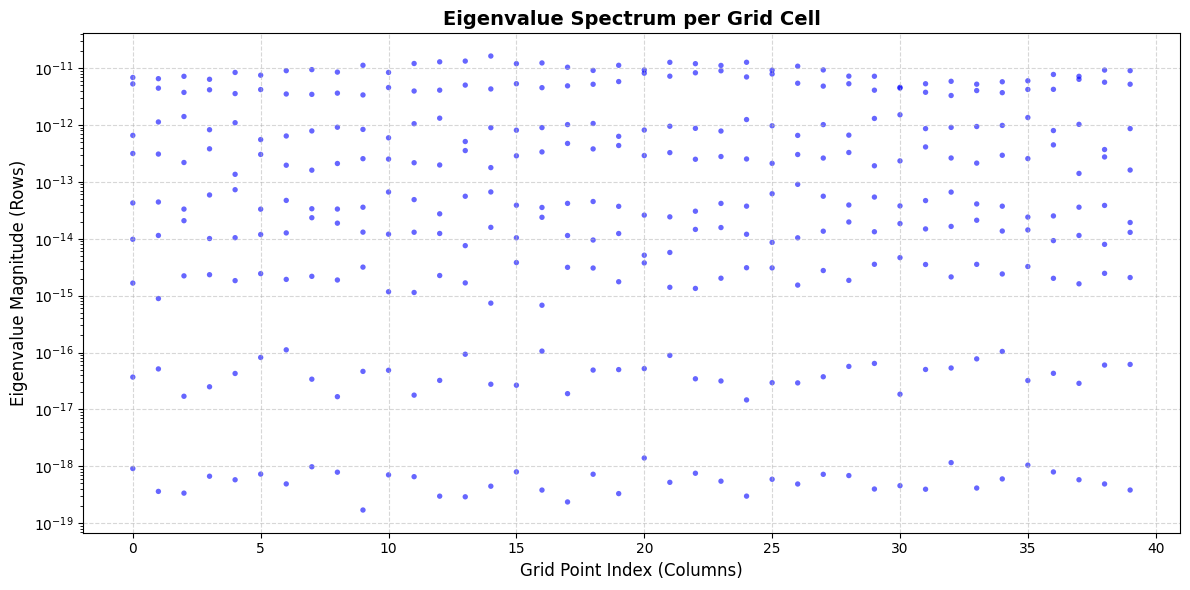

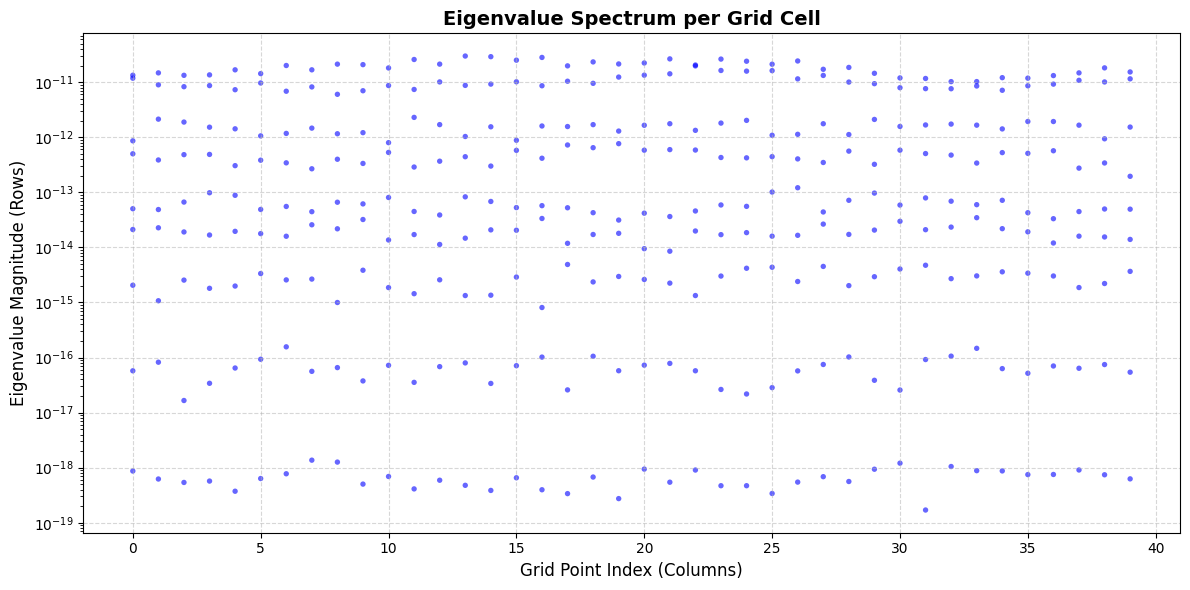

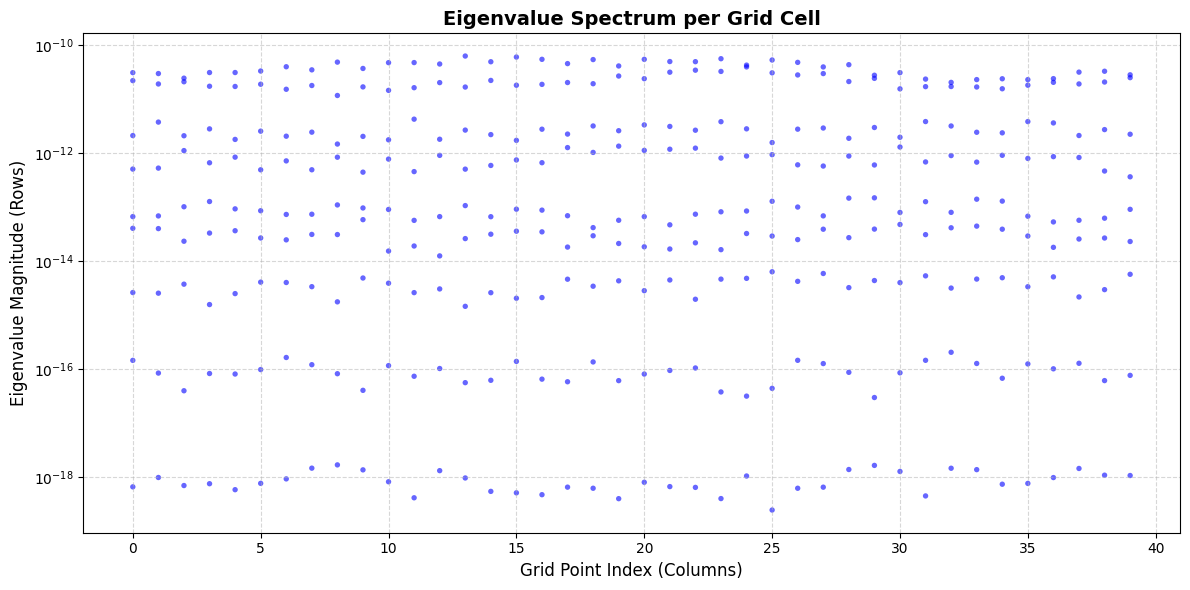

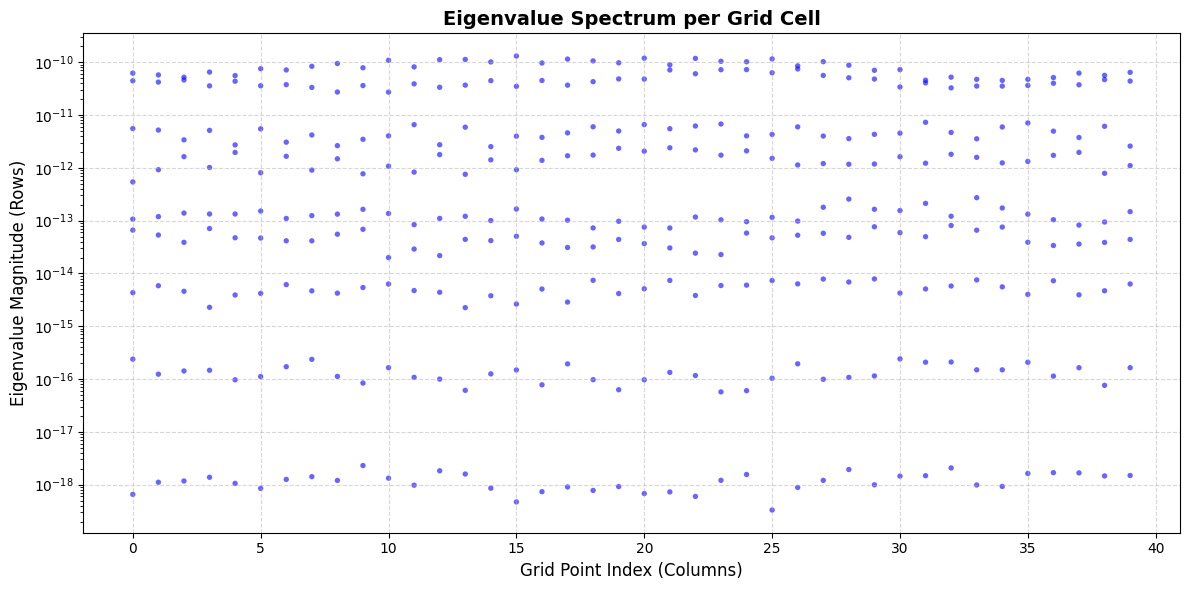

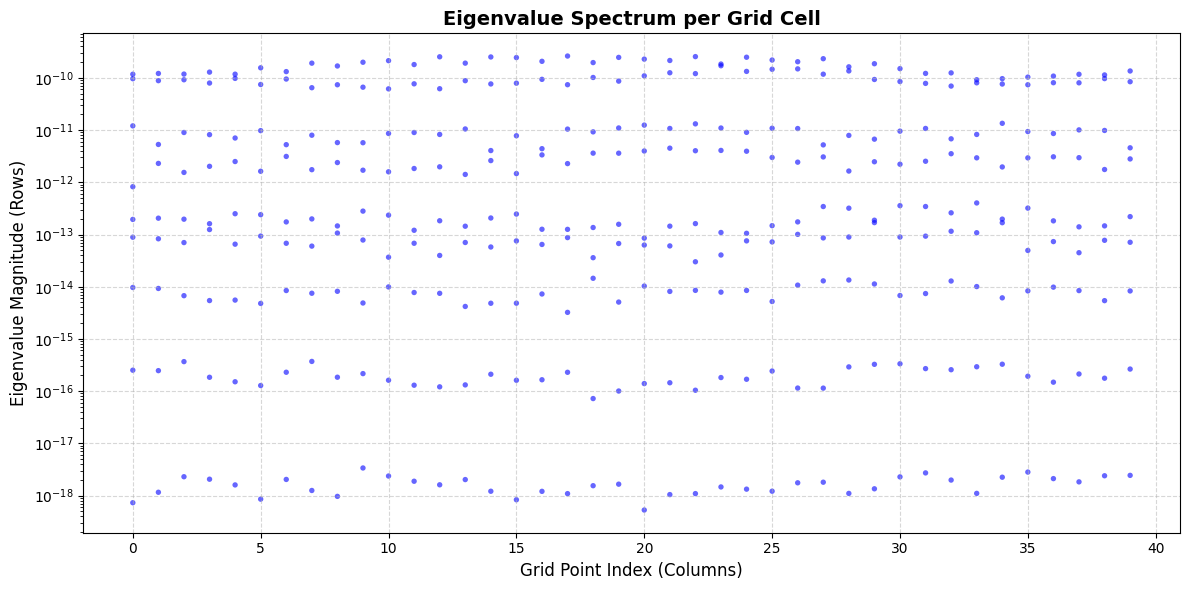

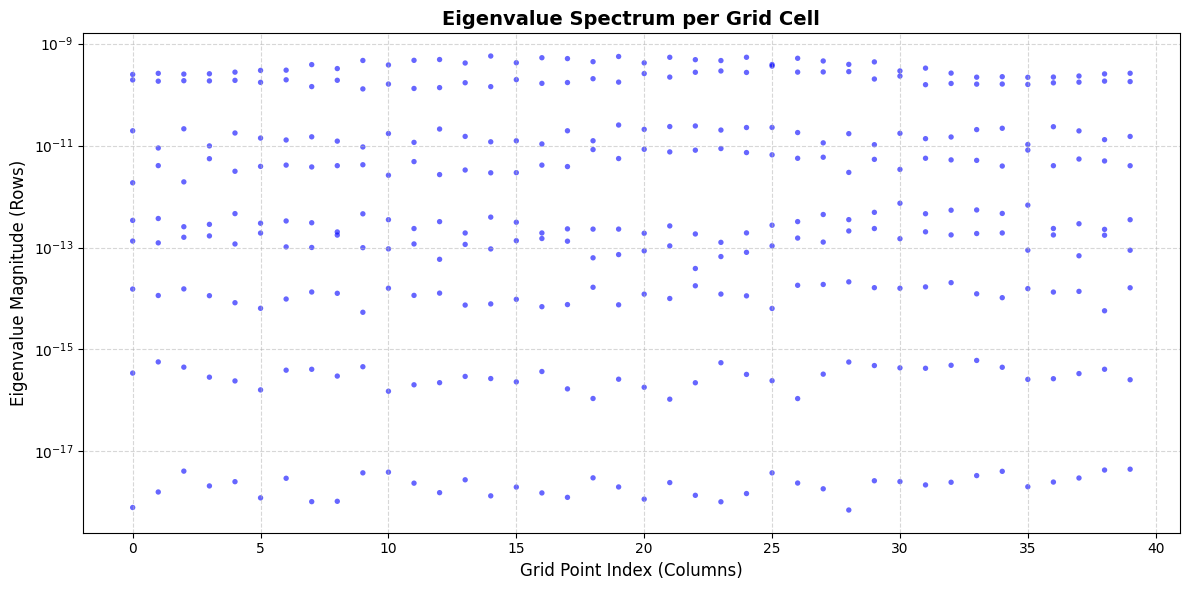

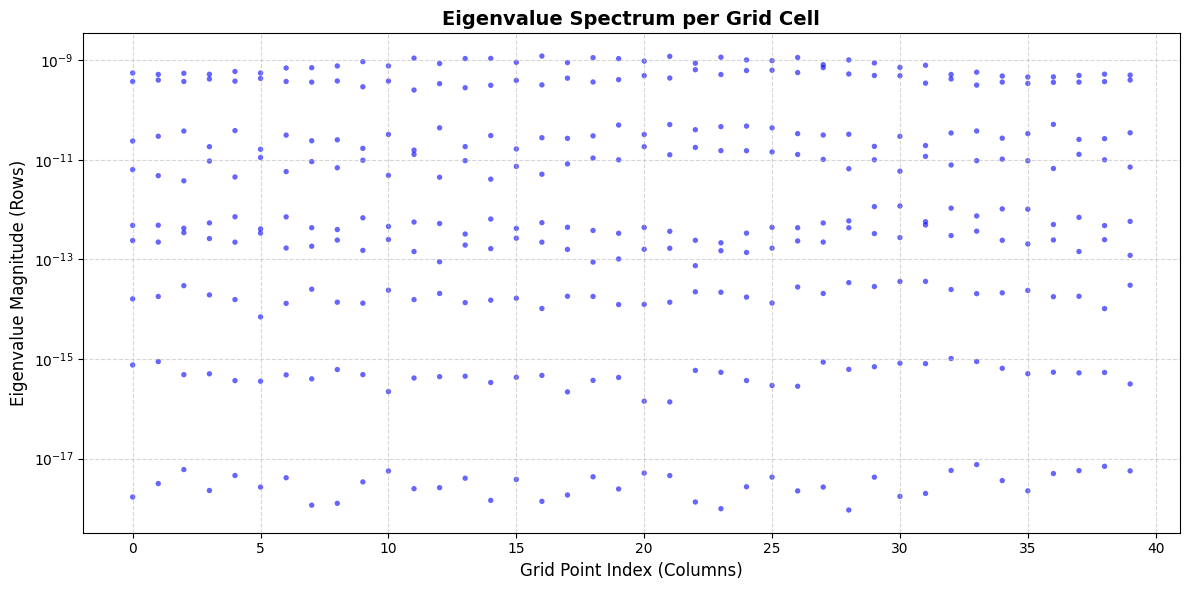

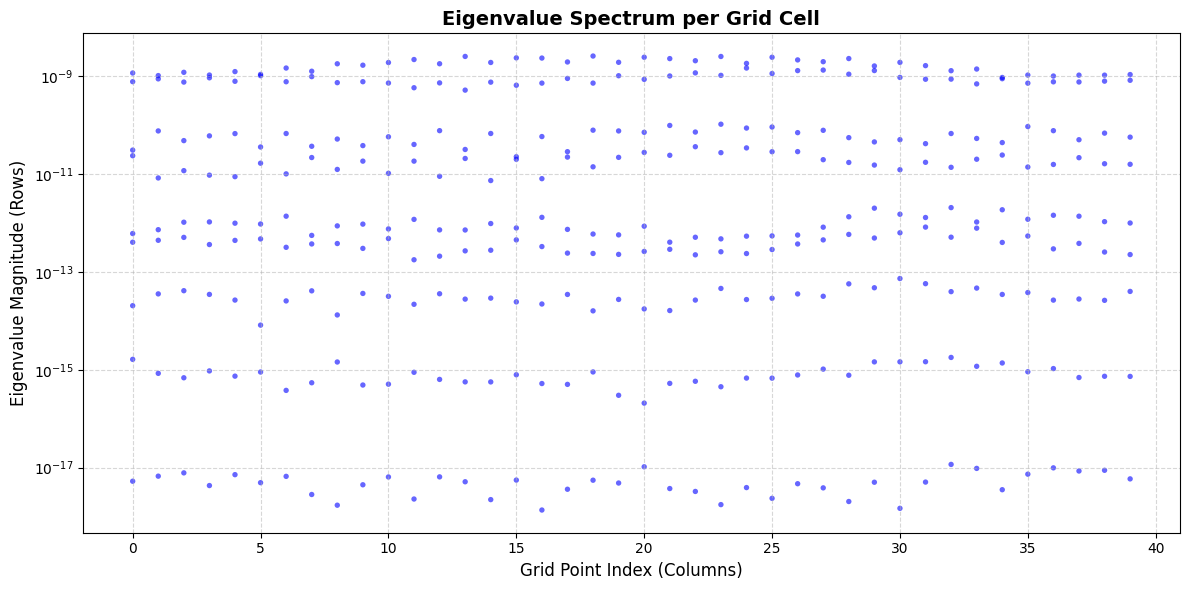

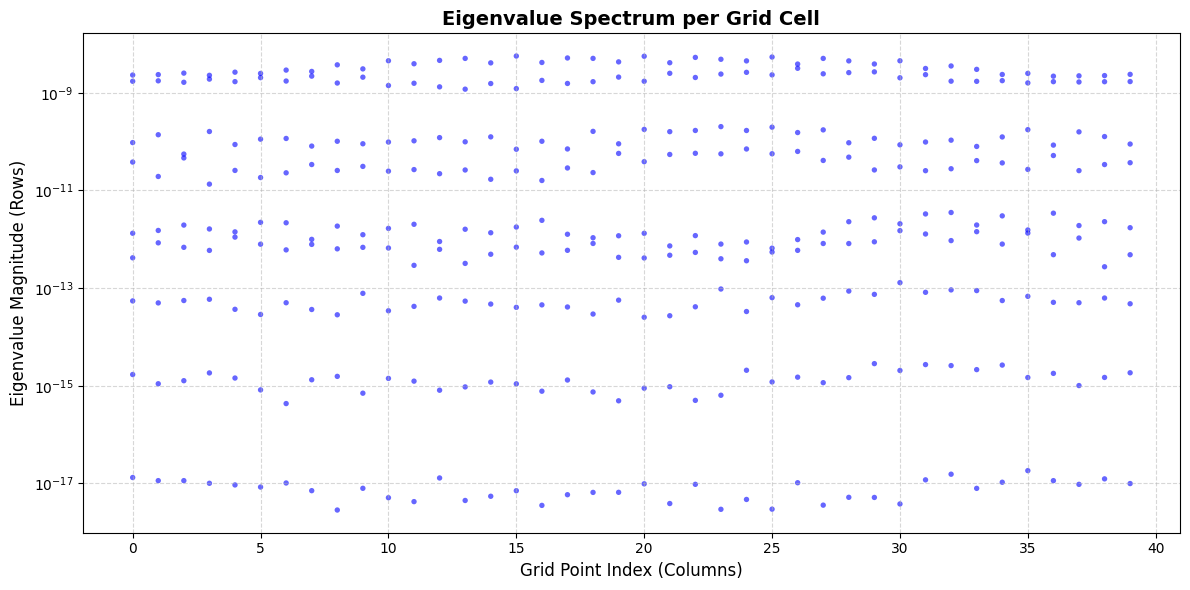

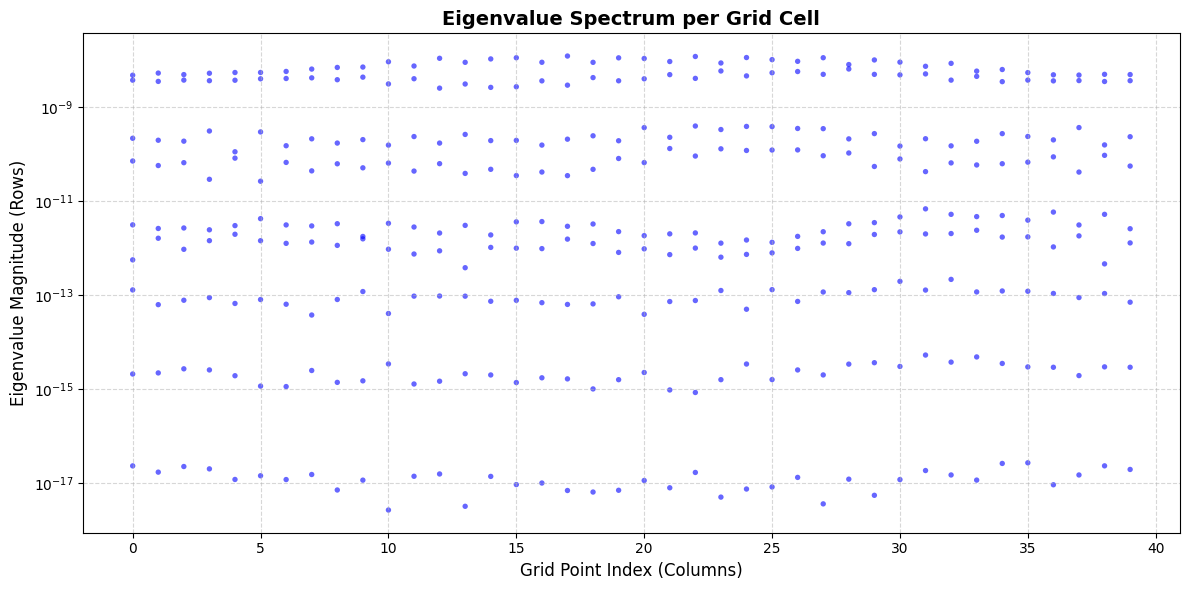

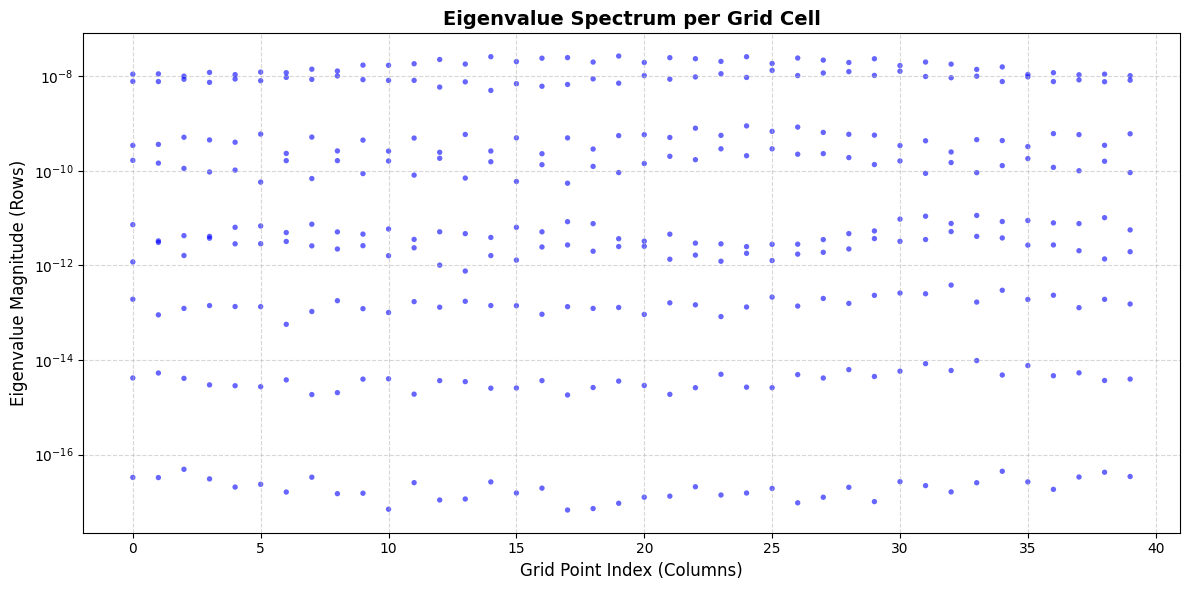

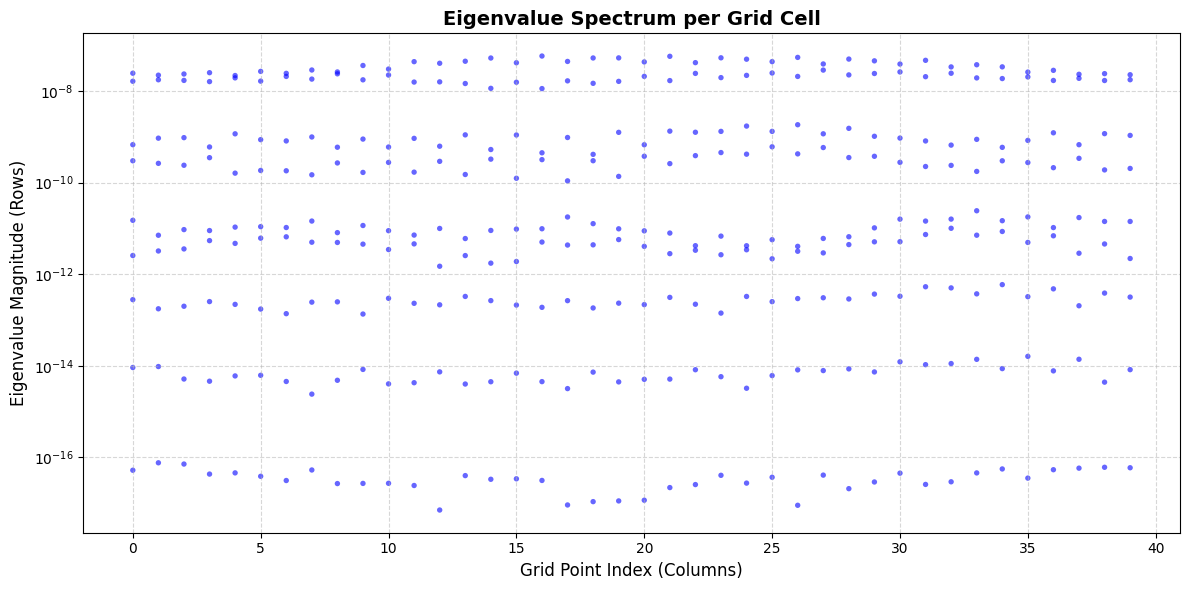

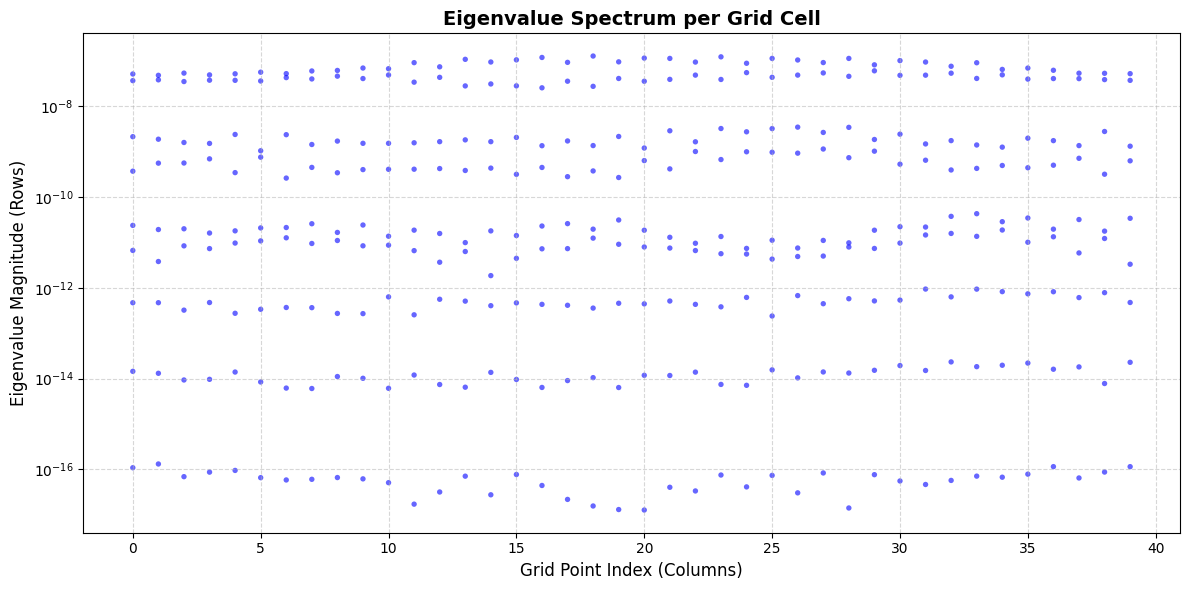

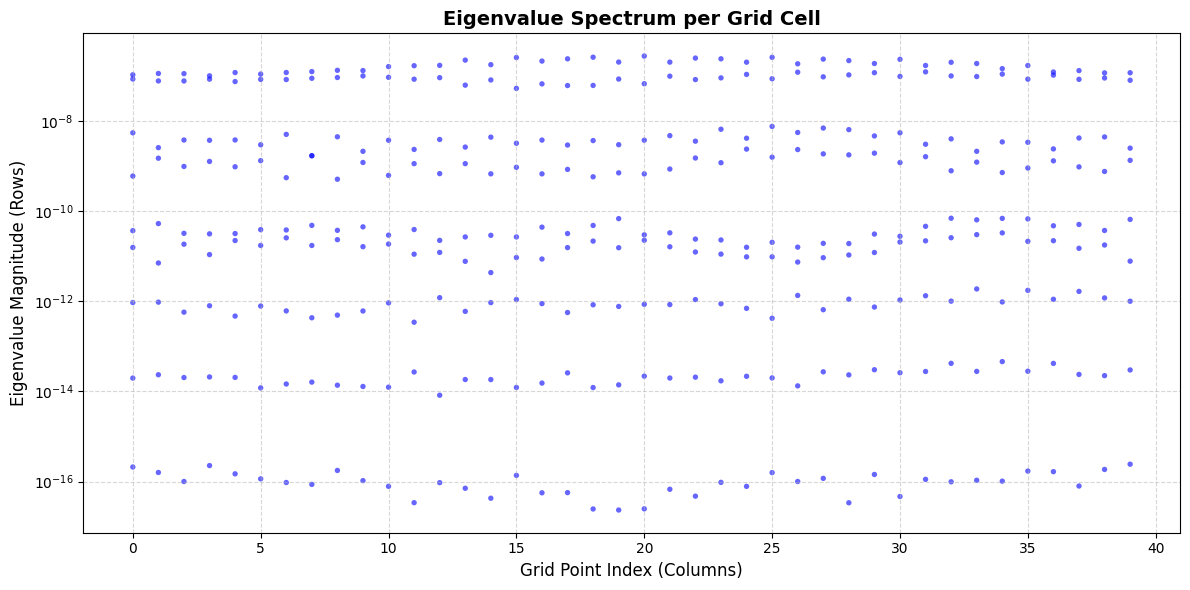

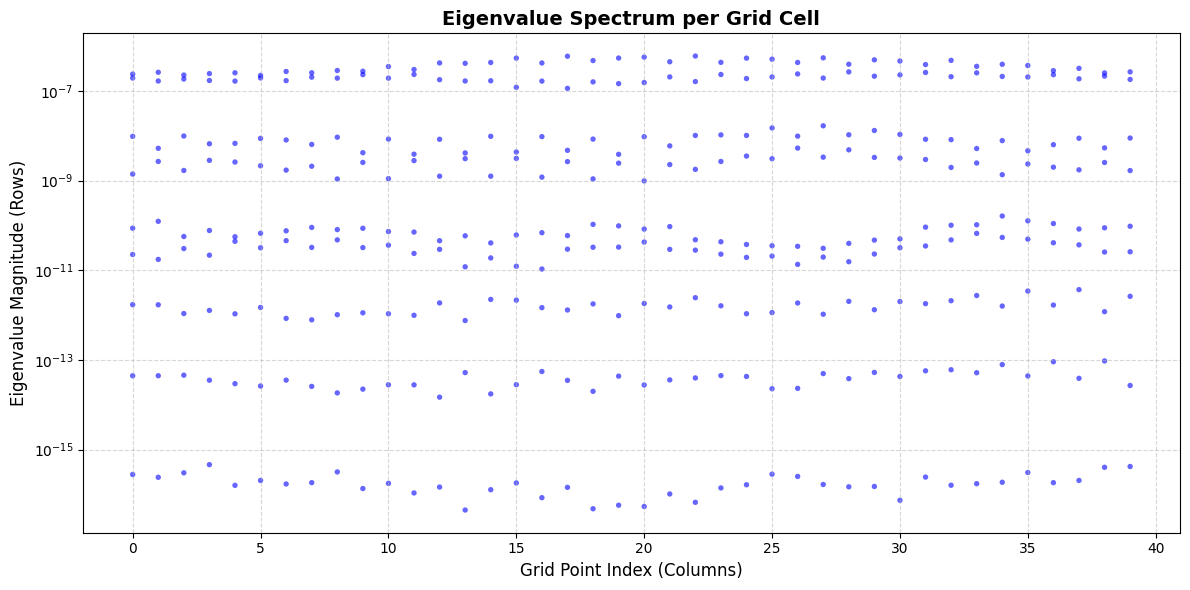

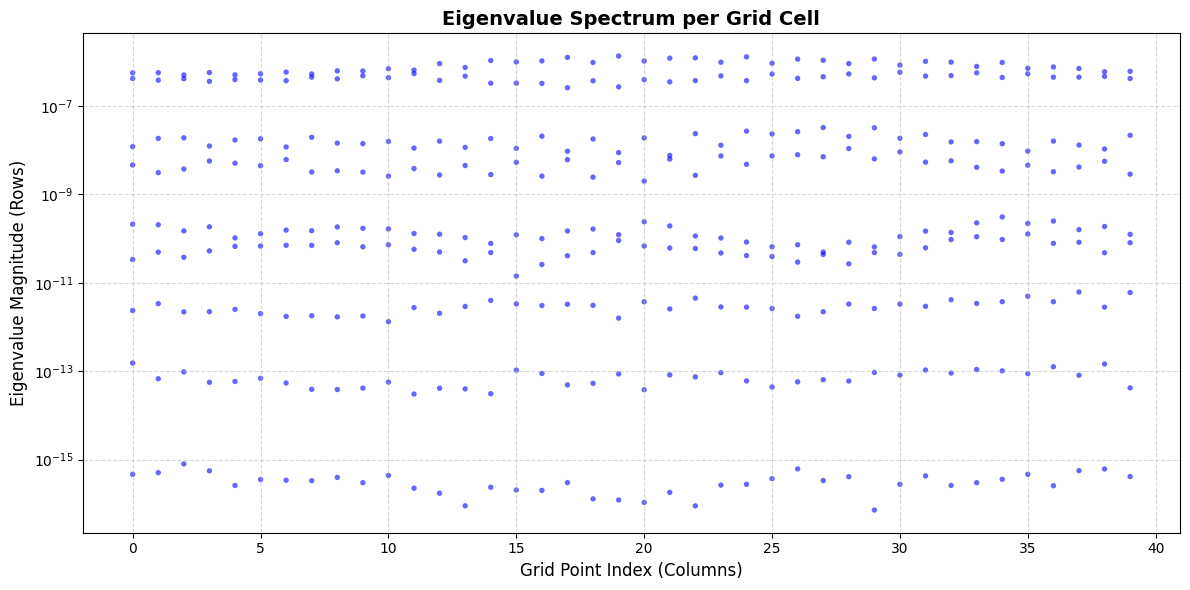

In [78]:
# Now that we have our ensembles generated we need to generate the LETLM, IETLM and GETLM for each time step
GETLMS = []
IETLMS = []
LETLMS = []

for i in range(len(Ensemble_final)-2):
    # We start by selecting the ensembles at each time level
    Chi = Ensemble_final[i+2]  # Future step matrix (N, ensemble_size)
    Xi  = Ensemble_final[i+1]  # Current step matrix (N, ensemble_size)
    X   = Ensemble_final[i]
    k = 1 # number of zero eigenvalue eigenvalues

    # We now make the GETLM
    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_RK4, model_parameters, ensemble_size_RK4, k, plot = True)
    GETLMS.append([N_tilde_G, L_tilde_G, K_tilde_G])

    # We will now make the IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_STENCIL_LARGE_RK4, model_parameters, ensemble_size_RK4)
    IETLM_temp = torch.pinverse(N_tilde_I) @ L_tilde_I
    IETLMS.append(IETLM_temp)

    # We will now make the LETLM
    M_tilde = LETLMC.LETLM_generator(Chi, Xi, LETLM_STENCIL_LARGE_RK4, model_parameters, ensemble_size_RK4)
    LETLMS.append(M_tilde)


tensor(0.)


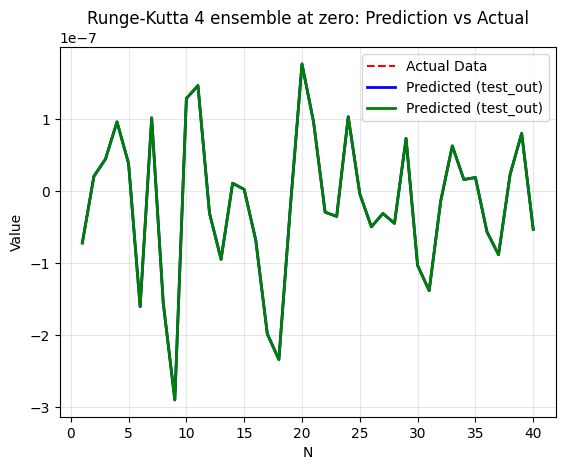

tensor(2.8040e-16)
TLM Test GETLM: tensor(9.6256e-06)
TLM Test IETLM: tensor(4.4390e-05)
TLM Test LETLM: tensor(2.8040e-16)
IETLM norm: tensor(0.0067)
LETLM norm: tensor(1.6745e-08)
GETLM norm: tensor(0.0031)


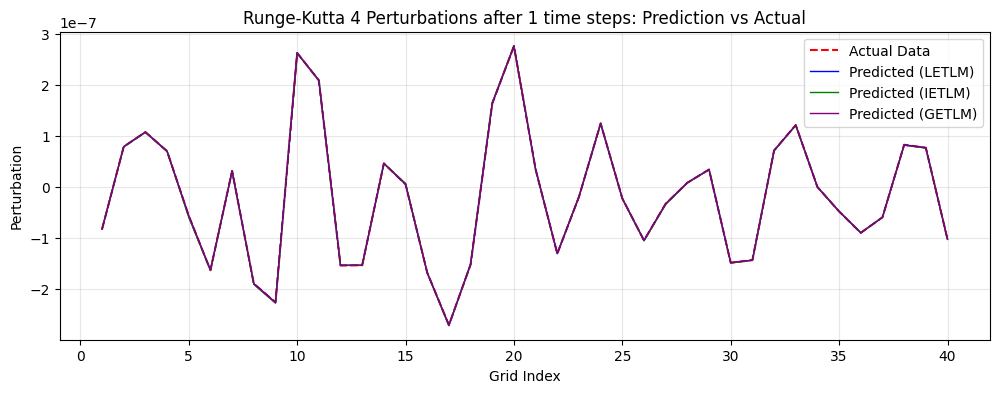

tensor(1.1528e-15)
TLM Test GETLM: tensor(2.3204e-05)
TLM Test IETLM: tensor(0.0001)
TLM Test LETLM: tensor(1.1528e-15)
IETLM norm: tensor(0.0110)
LETLM norm: tensor(3.3953e-08)
GETLM norm: tensor(0.0048)


<Figure size 640x480 with 0 Axes>

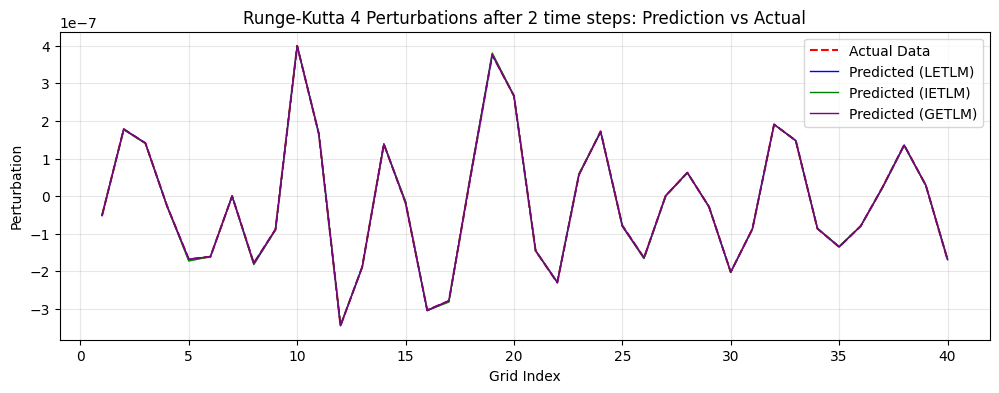

tensor(3.0575e-15)
TLM Test GETLM: tensor(3.2968e-05)
TLM Test IETLM: tensor(0.0002)
TLM Test LETLM: tensor(3.0575e-15)
IETLM norm: tensor(0.0146)
LETLM norm: tensor(5.5295e-08)
GETLM norm: tensor(0.0057)


<Figure size 640x480 with 0 Axes>

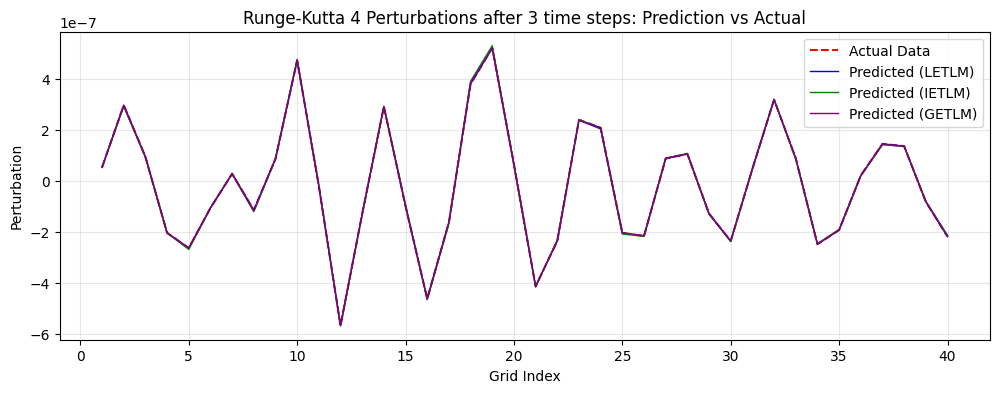

tensor(8.1892e-15)
TLM Test GETLM: tensor(3.9295e-05)
TLM Test IETLM: tensor(0.0003)
TLM Test LETLM: tensor(8.1892e-15)
IETLM norm: tensor(0.0174)
LETLM norm: tensor(9.0494e-08)
GETLM norm: tensor(0.0063)


<Figure size 640x480 with 0 Axes>

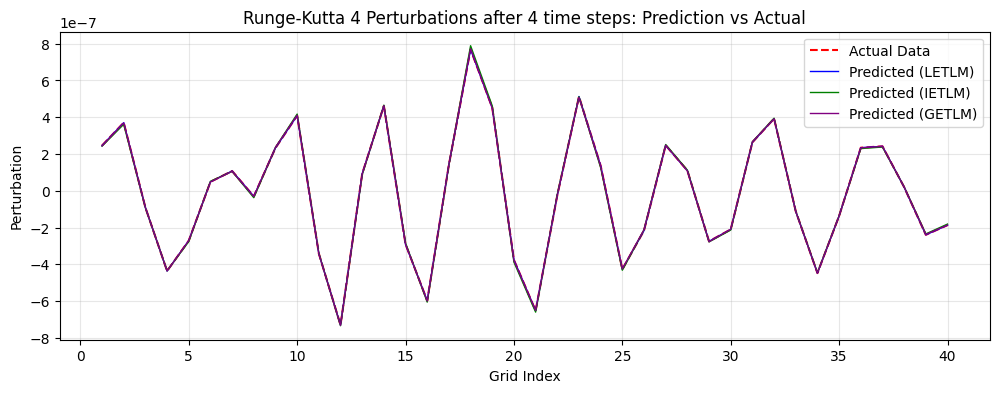

tensor(1.5434e-14)
TLM Test GETLM: tensor(4.2793e-05)
TLM Test IETLM: tensor(0.0004)
TLM Test LETLM: tensor(1.5434e-14)
IETLM norm: tensor(0.0198)
LETLM norm: tensor(1.2423e-07)
GETLM norm: tensor(0.0065)


<Figure size 640x480 with 0 Axes>

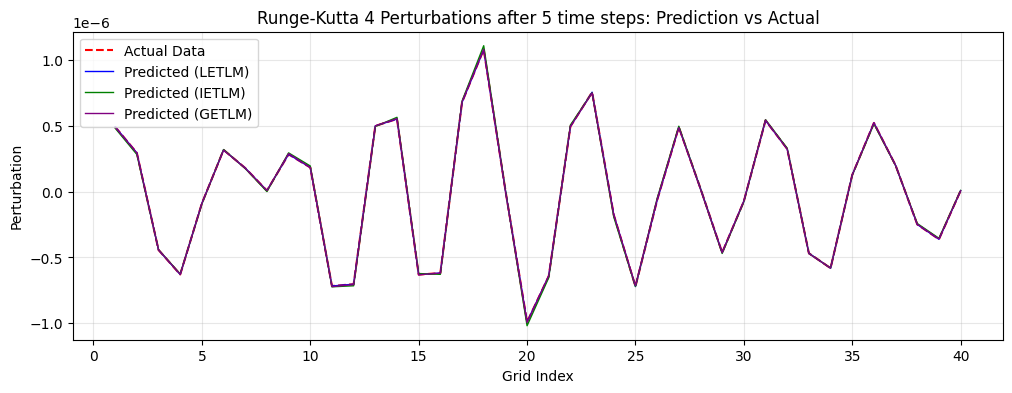

tensor(3.7602e-14)
TLM Test GETLM: tensor(4.4823e-05)
TLM Test IETLM: tensor(0.0005)
TLM Test LETLM: tensor(3.7602e-14)
IETLM norm: tensor(0.0218)
LETLM norm: tensor(1.9391e-07)
GETLM norm: tensor(0.0067)


<Figure size 640x480 with 0 Axes>

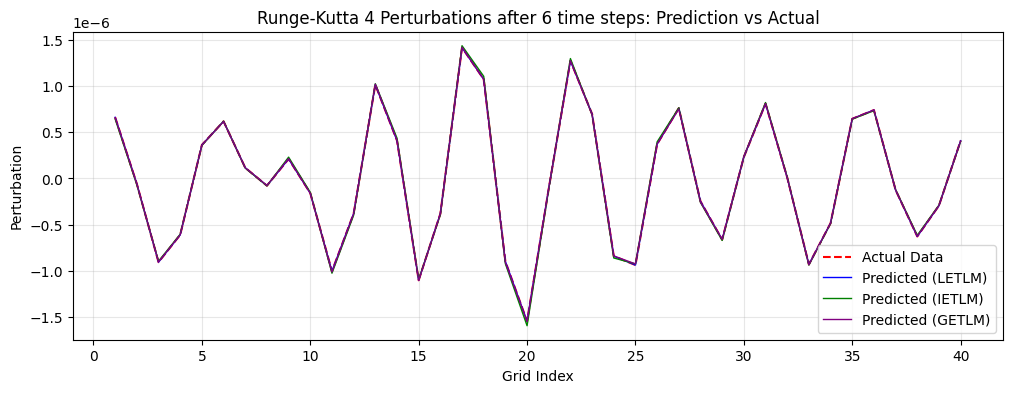

tensor(8.3552e-14)
TLM Test GETLM: tensor(4.5192e-05)
TLM Test IETLM: tensor(0.0005)
TLM Test LETLM: tensor(8.3552e-14)
IETLM norm: tensor(0.0231)
LETLM norm: tensor(2.8905e-07)
GETLM norm: tensor(0.0067)


<Figure size 640x480 with 0 Axes>

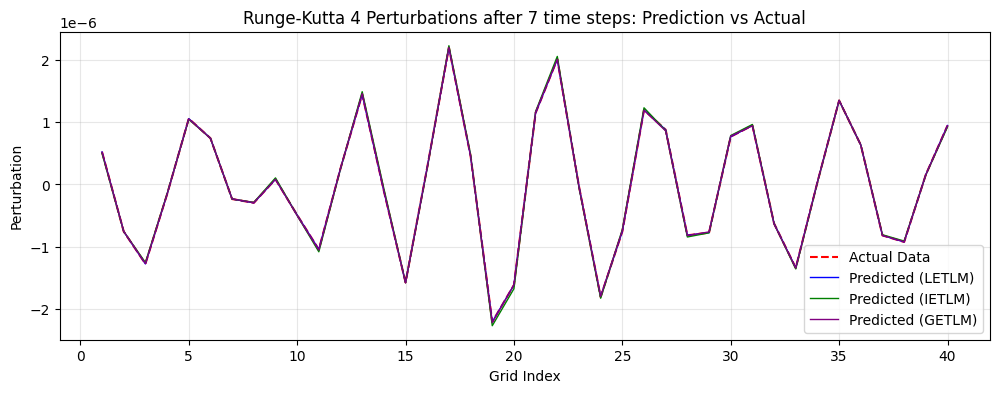

tensor(1.3767e-13)
TLM Test GETLM: tensor(4.4713e-05)
TLM Test IETLM: tensor(0.0006)
TLM Test LETLM: tensor(1.3767e-13)
IETLM norm: tensor(0.0240)
LETLM norm: tensor(3.7104e-07)
GETLM norm: tensor(0.0067)


<Figure size 640x480 with 0 Axes>

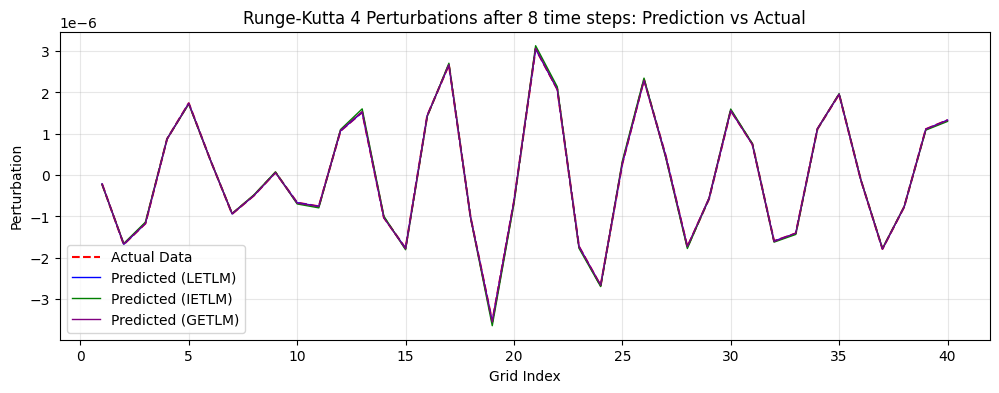

tensor(2.7565e-13)
TLM Test GETLM: tensor(4.4269e-05)
TLM Test IETLM: tensor(0.0006)
TLM Test LETLM: tensor(2.7565e-13)
IETLM norm: tensor(0.0246)
LETLM norm: tensor(5.2503e-07)
GETLM norm: tensor(0.0067)


<Figure size 640x480 with 0 Axes>

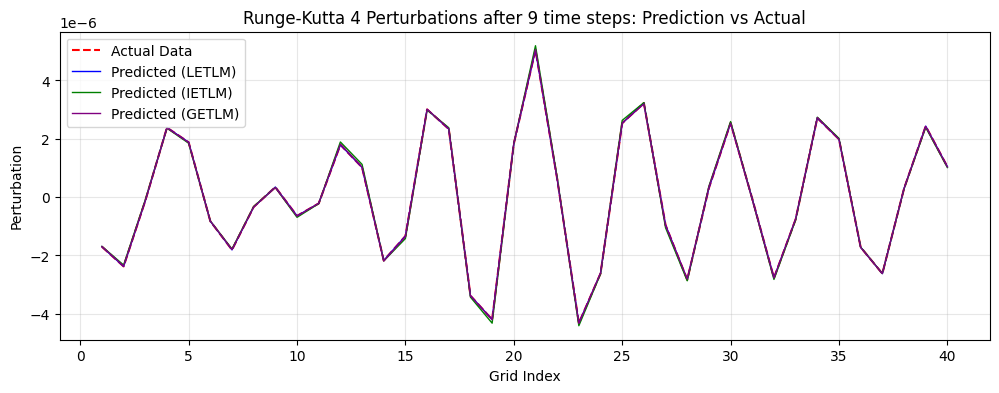

tensor(3.4495e-13)
TLM Test GETLM: tensor(4.3876e-05)
TLM Test IETLM: tensor(0.0006)
TLM Test LETLM: tensor(3.4495e-13)
IETLM norm: tensor(0.0252)
LETLM norm: tensor(5.8732e-07)
GETLM norm: tensor(0.0066)


<Figure size 640x480 with 0 Axes>

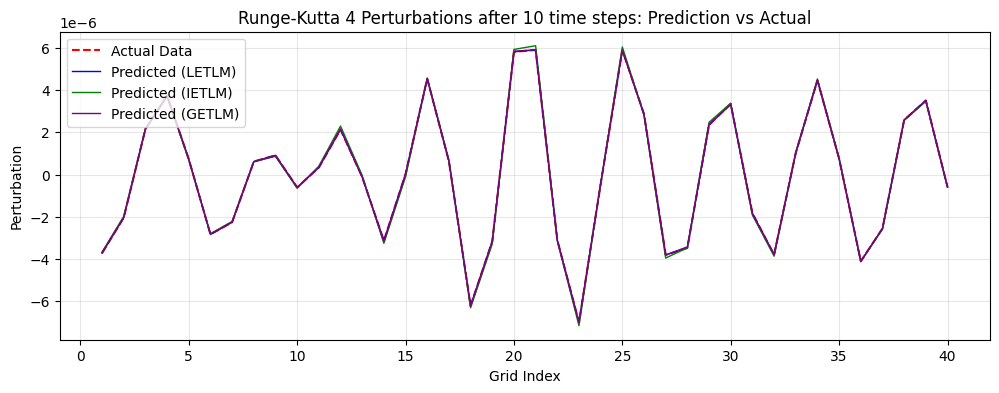

tensor(4.9488e-13)
TLM Test GETLM: tensor(4.3307e-05)
TLM Test IETLM: tensor(0.0007)
TLM Test LETLM: tensor(4.9488e-13)
IETLM norm: tensor(0.0257)
LETLM norm: tensor(7.0348e-07)
GETLM norm: tensor(0.0066)


<Figure size 640x480 with 0 Axes>

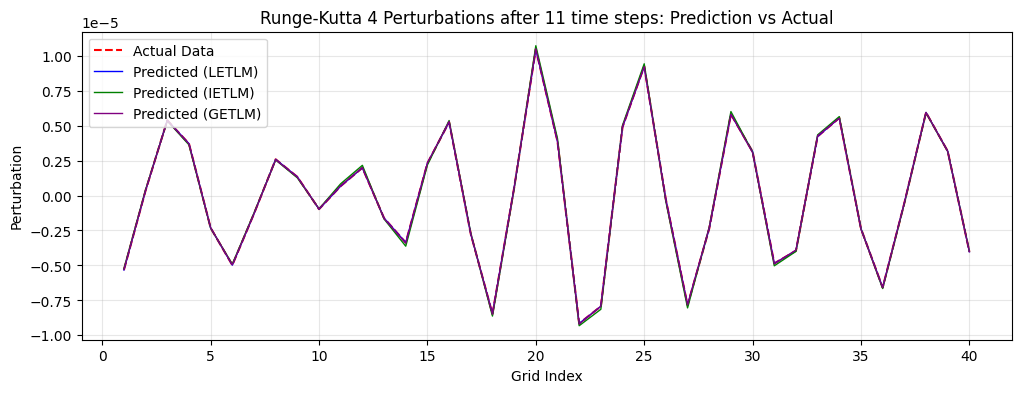

tensor(9.9354e-13)
TLM Test GETLM: tensor(4.2656e-05)
TLM Test IETLM: tensor(0.0007)
TLM Test LETLM: tensor(9.9354e-13)
IETLM norm: tensor(0.0261)
LETLM norm: tensor(9.9676e-07)
GETLM norm: tensor(0.0065)


<Figure size 640x480 with 0 Axes>

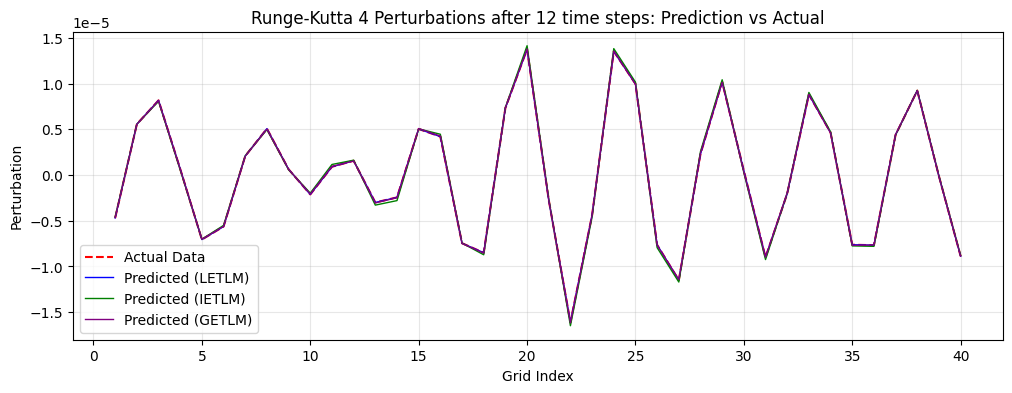

tensor(2.3721e-12)
TLM Test GETLM: tensor(4.2088e-05)
TLM Test IETLM: tensor(0.0007)
TLM Test LETLM: tensor(2.3721e-12)
IETLM norm: tensor(0.0264)
LETLM norm: tensor(1.5402e-06)
GETLM norm: tensor(0.0065)


<Figure size 640x480 with 0 Axes>

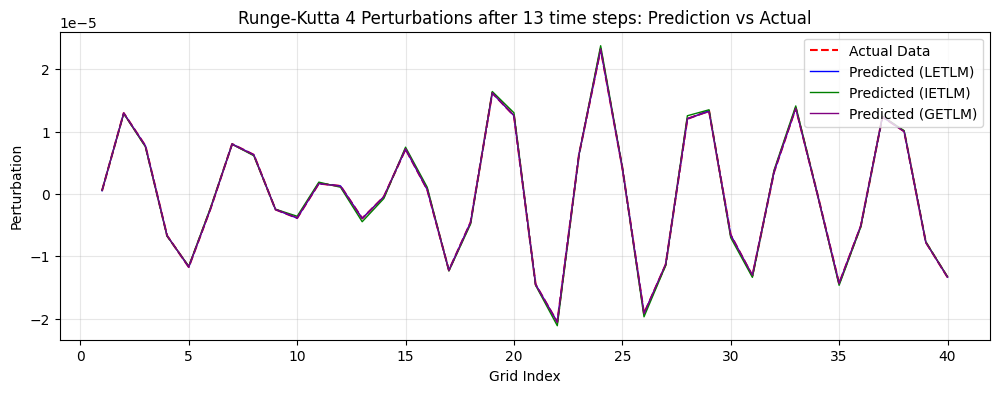

tensor(4.7682e-12)
TLM Test GETLM: tensor(4.1570e-05)
TLM Test IETLM: tensor(0.0007)
TLM Test LETLM: tensor(4.7682e-12)
IETLM norm: tensor(0.0267)
LETLM norm: tensor(2.1836e-06)
GETLM norm: tensor(0.0064)


<Figure size 640x480 with 0 Axes>

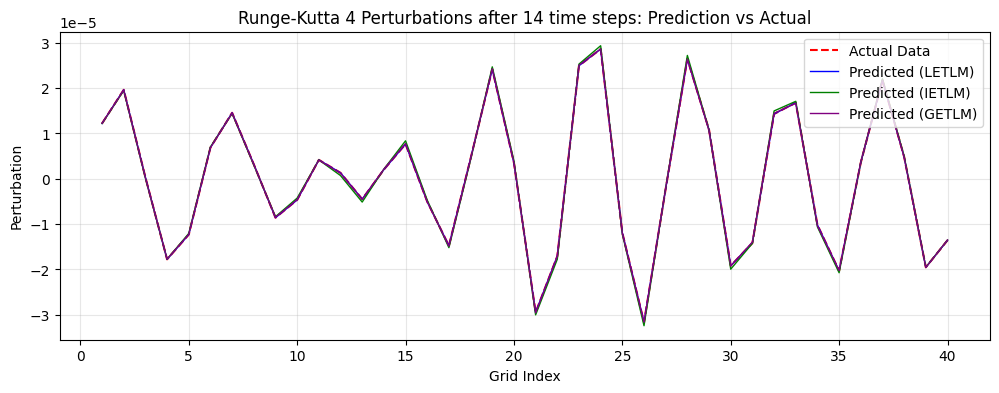

tensor(1.6681e-11)
TLM Test GETLM: tensor(4.1126e-05)
TLM Test IETLM: tensor(0.0007)
TLM Test LETLM: tensor(1.6681e-11)
IETLM norm: tensor(0.0270)
LETLM norm: tensor(4.0843e-06)
GETLM norm: tensor(0.0064)


<Figure size 640x480 with 0 Axes>

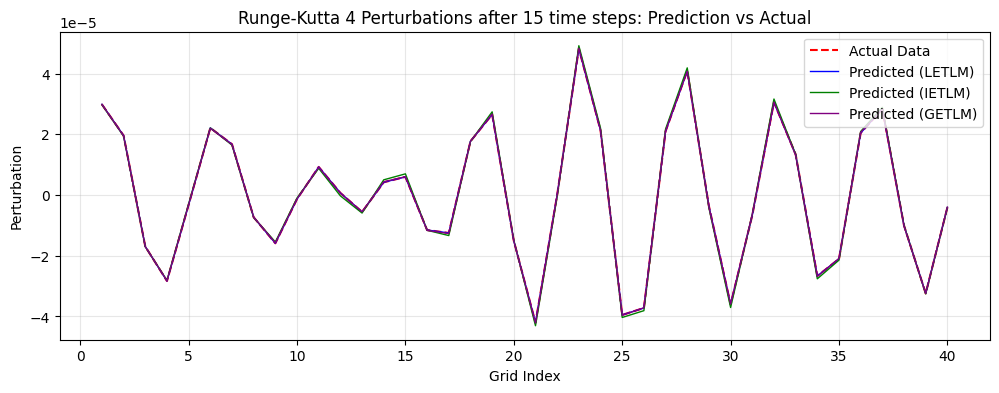

tensor(3.8709e-11)
TLM Test GETLM: tensor(4.0738e-05)
TLM Test IETLM: tensor(0.0007)
TLM Test LETLM: tensor(3.8709e-11)
IETLM norm: tensor(0.0274)
LETLM norm: tensor(6.2217e-06)
GETLM norm: tensor(0.0064)


<Figure size 640x480 with 0 Axes>

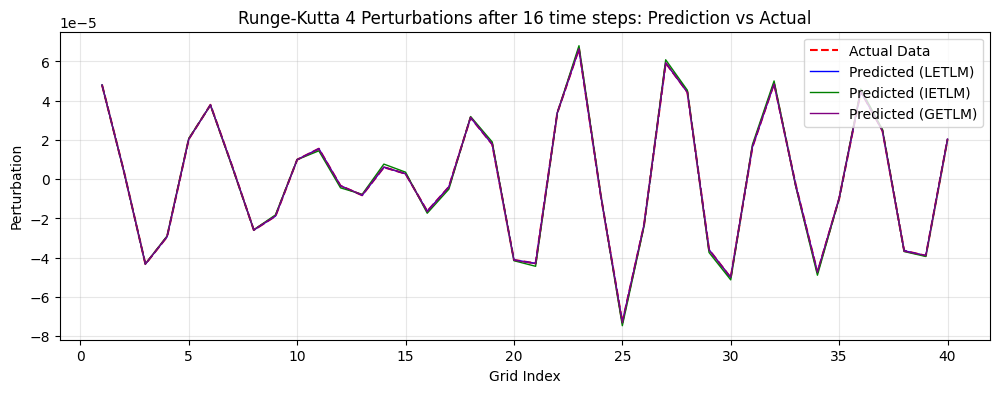

tensor(7.1147e-11)
TLM Test GETLM: tensor(4.0388e-05)
TLM Test IETLM: tensor(0.0008)
TLM Test LETLM: tensor(7.1147e-11)
IETLM norm: tensor(0.0277)
LETLM norm: tensor(8.4349e-06)
GETLM norm: tensor(0.0064)


<Figure size 640x480 with 0 Axes>

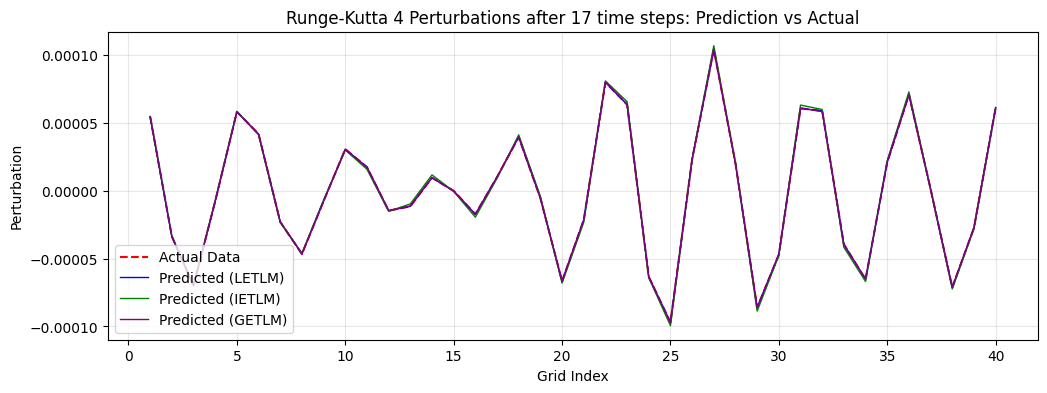

tensor(1.6588e-10)
TLM Test GETLM: tensor(4.0055e-05)
TLM Test IETLM: tensor(0.0008)
TLM Test LETLM: tensor(1.6588e-10)
IETLM norm: tensor(0.0279)
LETLM norm: tensor(1.2880e-05)
GETLM norm: tensor(0.0063)


<Figure size 640x480 with 0 Axes>

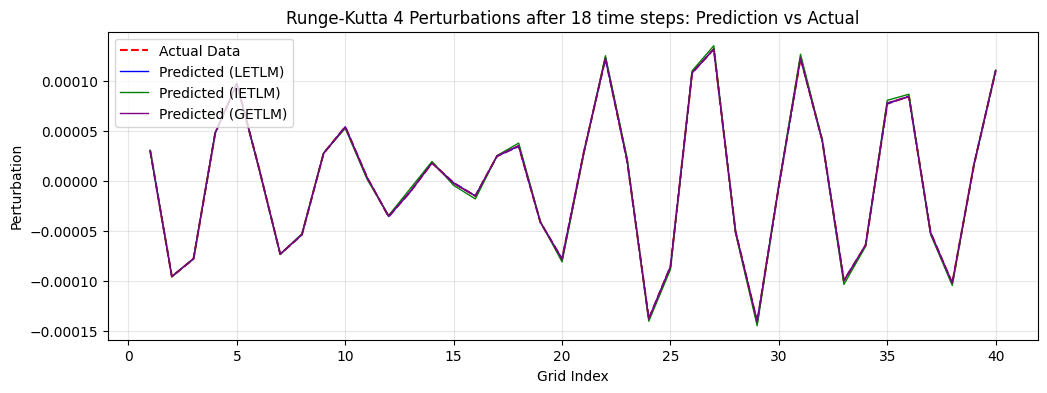

tensor(2.9675e-10)
TLM Test GETLM: tensor(3.9729e-05)
TLM Test IETLM: tensor(0.0008)
TLM Test LETLM: tensor(2.9675e-10)
IETLM norm: tensor(0.0282)
LETLM norm: tensor(1.7226e-05)
GETLM norm: tensor(0.0063)


<Figure size 640x480 with 0 Axes>

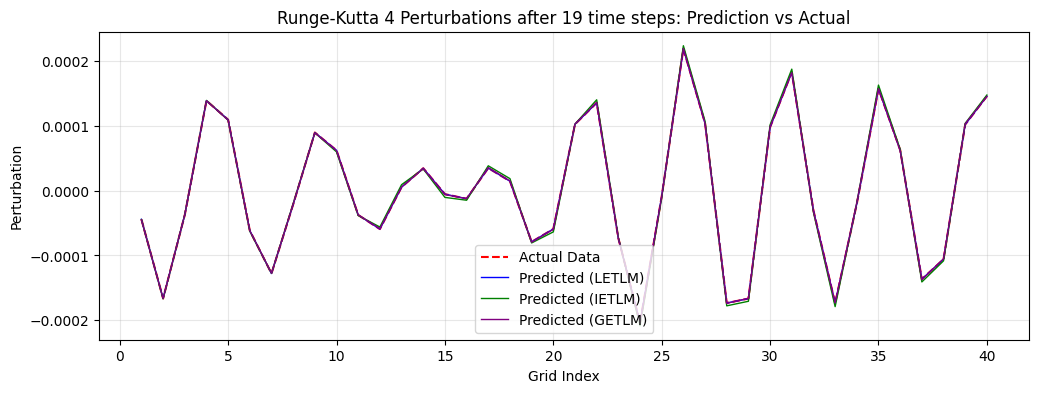

<Figure size 640x480 with 0 Axes>

In [79]:
# We will now compare the TLMS to the actual data to see 

# We first set a starting point for the TLMS
starting_time = 1

x_values = np.arange(1, N + 1)

LETLM_norm= []
IETLM_norm = []
GETLM_norm = []


LETLM_TT_result = []
IETLM_TT_result = []
GETLM_TT_result = []


# The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
test_0 = test_final_pert[1+starting_time]
LETLM_test = test_0
IETLM_test = test_0
GETLM_test_future = test_0
GETLM_test_current = test_final_pert[starting_time]

letlm_norm = L2_norm(LETLM_test, test_0)
ietlm_norm = L2_norm(IETLM_test, test_0)
getlm_norm = L2_norm(GETLM_test_future, test_0)



LETLM_norm.append(letlm_norm)
IETLM_norm.append(ietlm_norm)
GETLM_norm.append(getlm_norm)

index = 1+starting_time

LETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
IETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )

print(LETLM_TT)
LETLM_TT_result.append(LETLM_TT)
IETLM_TT_result.append(IETLM_TT)
GETLM_TT_result.append(GETLM_TT)





plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='blue', linewidth=2)
plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)
# plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

plt.title(f"Runge-Kutta 4 ensemble at zero: Prediction vs Actual")
plt.xlabel("N")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop

# We will now go through the steps to see how each of the TLMS goes 
for i in range(len(test_final_pert)-3):
    index = i+2 + starting_time
    test = test_final_pert[i+2 + starting_time]
    letlm = LETLMS[i+starting_time]
    # print(len(letlm))
    LETLM_test = letlm @ LETLM_test

    letlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], LETLM_test)
    print(letlm_tt)
    LETLM_TT_result.append(letlm_tt)
    # LETLM_TT = torch.cat((LETLM_TT, letlm_tt), dim = 0)


    # Ploting the IETLM
    ietlm = IETLMS[i+starting_time]
    IETLM_test = ietlm @ IETLM_test


    ietlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], IETLM_test)
    IETLM_TT_result.append(ietlm_tt)


    # IETLM_TT = torch.cat((IETLM_TT, ietlm_tt), dim = 0)



    GETLM_test_past = GETLM_test_current
    GETLM_test_current = GETLM_test_future

    NL = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][1]
    NK = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][2]
    GETLM_test_future = NL @ GETLM_test_current + NK @ GETLM_test_past

    getlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future)

    # GETLM_TT = torch.cat((GETLM_TT, getlm_tt), dim = 0)
    GETLM_TT_result.append(getlm_tt)

    print('TLM Test GETLM:', getlm_tt)
    print('TLM Test IETLM:', ietlm_tt)
    print('TLM Test LETLM:', letlm_tt)






    

    # We now need to calculate the L2 norm

    letlm_norm = L2_norm(LETLM_test, test)
    ietlm_norm = L2_norm(IETLM_test, test)
    getlm_norm = L2_norm(GETLM_test_future, test)
    print('IETLM norm:', ietlm_norm)
    print('LETLM norm:', letlm_norm)
    print('GETLM norm:', getlm_norm)
    LETLM_norm.append(letlm_norm)
    IETLM_norm.append(ietlm_norm)
    GETLM_norm.append(getlm_norm)

    plt.figure(figsize=(12, 4))  # width=12 inches, height=4 inches
    plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
    plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (LETLM)', color='blue', linewidth=1)
    plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (GETLM)', color='purple', linewidth=1)

    plt.title(f"Runge-Kutta 4 Perturbations after {i+1} time steps: Prediction vs Actual")
    plt.xlabel("Grid Index")
    plt.ylabel("Perturbation")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show() # This creates a fresh window/plot for each step in the loop
    plt.clf()
    

    
    # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    # plt.show()
    # plt.clf()



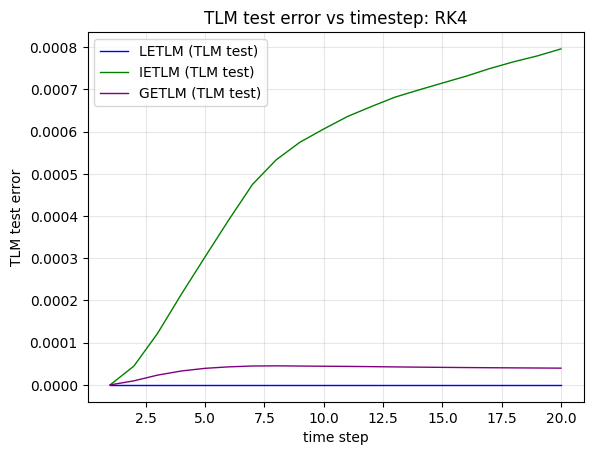

<Figure size 640x480 with 0 Axes>

In [80]:
x_values_norm = np.arange(1,len(IETLM_norm)+1)

plt.plot(x_values_norm, LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: RK4")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2921216659.py:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, LETLM_TT_result/LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2921216659.py:6: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, IETLM_TT_result/LETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2921216659.py:7: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, GETLM_TT_result/LETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)


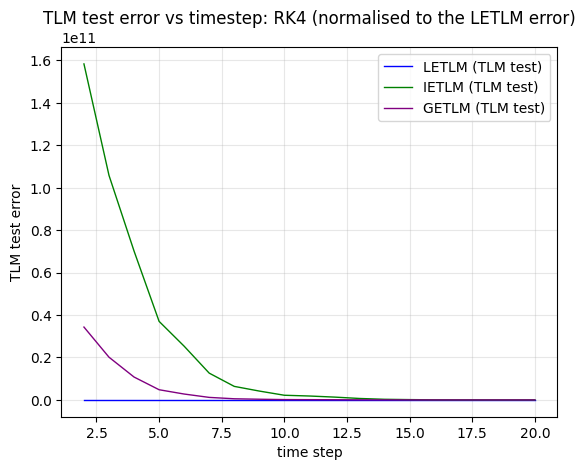

<Figure size 640x480 with 0 Axes>

In [81]:
LETLM_TT_result = np.array(LETLM_TT_result)
IETLM_TT_result = np.array(IETLM_TT_result)
GETLM_TT_result = np.array(GETLM_TT_result)

plt.plot(x_values_norm, LETLM_TT_result/LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_TT_result/LETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_TT_result/LETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: RK4 (normalised to the LETLM error)")
plt.xlabel("time step")
plt.ylabel("TLM test error")
# plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

In [82]:
# # We will now compare the TLMS to the actual data to see 

# # We first set a starting point for the TLMS
# starting_time = 1

# x_values = np.arange(1, N + 1)

# LETLM_norm= []
# IETLM_norm = []
# GETLM_norm = []

# # The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
# test_0 = test_final[1+starting_time]
# LETLM_test = test_0
# IETLM_test = test_0
# GETLM_test_future = test_0
# GETLM_test_current = test_final[starting_time]

# letlm_norm = L2_norm(LETLM_test, test_0)
# ietlm_norm = L2_norm(IETLM_test, test_0)
# getlm_norm = L2_norm(GETLM_test_future, test_0)

# LETLM_norm.append(letlm_norm)
# IETLM_norm.append(ietlm_norm)
# GETLM_norm.append(getlm_norm)

# plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
# plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='blue', linewidth=2)
# plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)
# plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

# plt.title(f"Ensemble at zero: Prediction vs Actual")
# plt.xlabel("N")
# plt.ylabel("Value")
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.show() # This creates a fresh window/plot for each step in the loop

# # We will now go through the steps to see how each of the TLMS goes 
# for i in range(len(test_final)-3):
#     test = test_final[i+2 + starting_time]
#     letlm = LETLMS[i+starting_time][0]
#     # print(len(letlm))
#     LETLM_test = letlm @ LETLM_test


#     # Ploting the IETLM
#     ietlm = IETLMS[i+starting_time]
#     # plt.imshow(ietlm,aspect='auto', cmap='viridis')
#     # plt.colorbar(label='Value')
#     # plt.title("2D Tensor Heatmap")
#     # plt.title("N_tilde")
#     # plt.show()

#     GETLM_test_past = GETLM_test_current
#     GETLM_test_current = GETLM_test_future

#     NL = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][1]
#     NK = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][2]
#     GETLM_test_future = NL @ GETLM_test_current + NK @ GETLM_test_past



#     IETLM_test = ietlm @ IETLM_test

#     # We now need to calculate the L2 norm

#     letlm_norm = L2_norm(LETLM_test, test)
#     ietlm_norm = L2_norm(IETLM_test, test)
#     getlm_norm = L2_norm(GETLM_test_future, test)
#     LETLM_norm.append(letlm_norm)
#     IETLM_norm.append(ietlm_norm)
#     GETLM_norm.append(getlm_norm)


#     plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
#     plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (LETLM)', color='blue', linewidth=1)
#     plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
#     plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (GETLM)', color='purple', linewidth=1)

#     plt.title(f"Ensemble {i+1}: Prediction vs Actual")
#     plt.xlabel("N")
#     plt.ylabel("Value")
#     plt.legend()
#     plt.grid(True, alpha=0.3)
#     plt.show() # This creates a fresh window/plot for each step in the loop
#     plt.clf()
#     print('IETLM norm:', ietlm_norm)
#     print('LETLM norm:', letlm_norm)
#     print('GETLM norm:', getlm_norm)

    
#     # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
#     # plt.show()
#     # plt.clf()



In [83]:
# x_values_norm = np.arange(1,len(IETLM_norm)+1)
# plt.yscale('log')
# plt.plot(x_values_norm, LETLM_norm, label='LETLM', color='blue', linewidth=1)
# plt.plot(x_values_norm, IETLM_norm, label='IETLM', color='green', linewidth=1)
# plt.plot(x_values_norm, GETLM_norm, label='GETLM', color='purple', linewidth=1)
# plt.title("L2 norm error vs timestep: Runge-Kutta 4")
# plt.xlabel("time step")
# plt.ylabel("L2 Norm error")
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.show() # This creates a fresh window/plot for each step in the loop
# plt.clf()


In [84]:
# We will also repeat this for Leapfrog
# The first step is to the parameters for out model

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.1 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)
model = TST.AB2_L96
x_values = np.arange(1, N+1)  
spin_up_time = 10000

In [85]:
# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in tqdm(range(spin_up_time-1)):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)

100%|██████████| 9999/9999 [00:00<00:00, 38267.81it/s]


In [86]:
# Now that the model is spun up, we need to generate the ensembles

# The first step to do this is to work out what we want to use as our stencil
stencil_members_future_LF = [0]
stencil_members_current_LF = [-2,-1,0,1]
stencil_members_past_LF = [-2,-1,0,1] #[0]
stencil_members_large_LF = [stencil_members_future_LF, stencil_members_current_LF, stencil_members_past_LF]

# Now that we have our stencil we can calculate how many ensemble members we need 
ensemble_size_LF = 9 + len(stencil_members_future_LF) + len(stencil_members_current_LF) + len(stencil_members_past_LF)

# We now need to set the size of the perturbation that we will use for generating the ensemble TLMS
SD_pert = 10**(-7)

# We also need to define our test perturbation
Test_pert_current = torch.randn(N) * SD_pert
Test_pert_past = torch.randn(N) * SD_pert
Test_pert = (Test_pert_current, Test_pert_past)


test_final_pert, Ensemble_final, Ensembles, test_guess, unpert_run =  GETLMC.GETLM_ensemble_generator_mult(x_out, ensemble_size_LF, SD_pert, model, model_parameters, Test_pert, number_of_steps = 12)


In [87]:
IETLM_STENCIL_LARGE_LF = [[-2,-1,0,1],[-2,-1,0,1]]
LETLM_STENCIL_LARGE_LF = [[0],[-8,7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6]]

In [88]:
# Now that we have our ensembles generated we need to generate the LETLM, IETLM and GETLM for each time step
GETLMS = []
IETLMS = []
LETLMS = []

for i in range(len(Ensemble_final)-2):
    # We start by selecting the ensembles at each time level
    Chi = Ensemble_final[i+2]  # Future step matrix (N, ensemble_size)
    Xi  = Ensemble_final[i+1]  # Current step matrix (N, ensemble_size)
    X   = Ensemble_final[i]
    k = 1 # number of zero eigenvalue eigenvalues

    # We now make the GETLM
    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_LF, model_parameters, ensemble_size_LF, k, plot = False)
    
    GETLMS.append([N_tilde_G, L_tilde_G, K_tilde_G])

    # We will now make the IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_STENCIL_LARGE_LF, model_parameters, ensemble_size_LF)
    IETLM_temp = torch.pinverse(N_tilde_I) @ L_tilde_I
    IETLMS.append(IETLM_temp)

    # We will now make the LETLM
    M_tilde = LETLMC.LETLM_generator(Chi, Xi, LETLM_STENCIL_LARGE_LF, model_parameters, ensemble_size_LF)
    LETLMS.append(M_tilde)


tensor(0.)


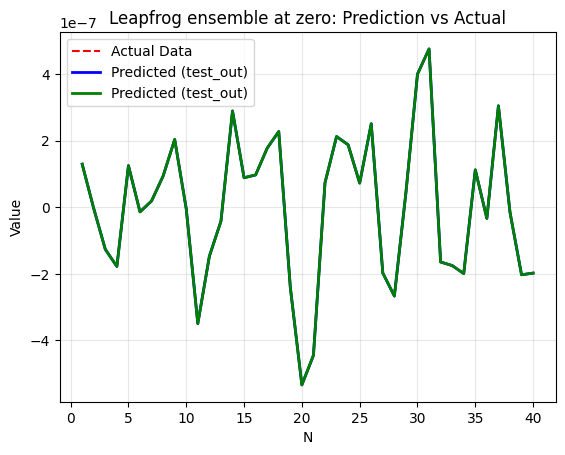

tensor(0.0059)
IETLM norm: tensor(0.0687)
LETLM norm: tensor(0.0767)
GETLM norm: tensor(3.5530e-08)


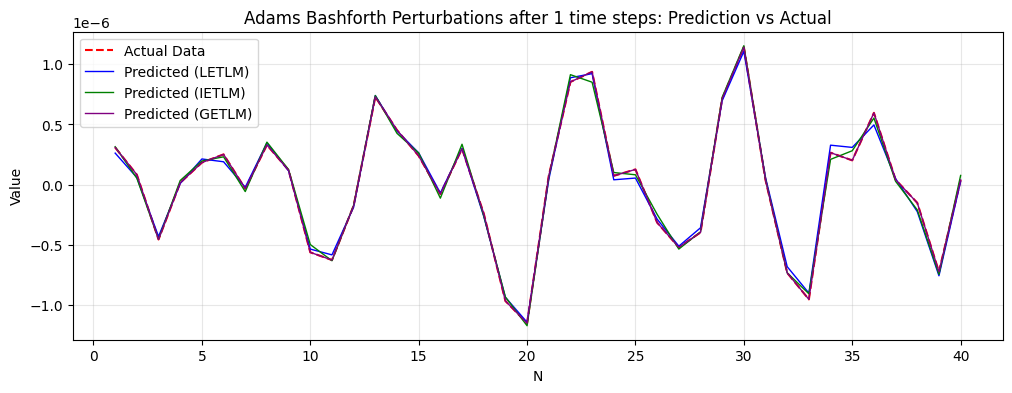

tensor(0.0040)
IETLM norm: tensor(0.0515)
LETLM norm: tensor(0.0634)
GETLM norm: tensor(9.8192e-08)


<Figure size 640x480 with 0 Axes>

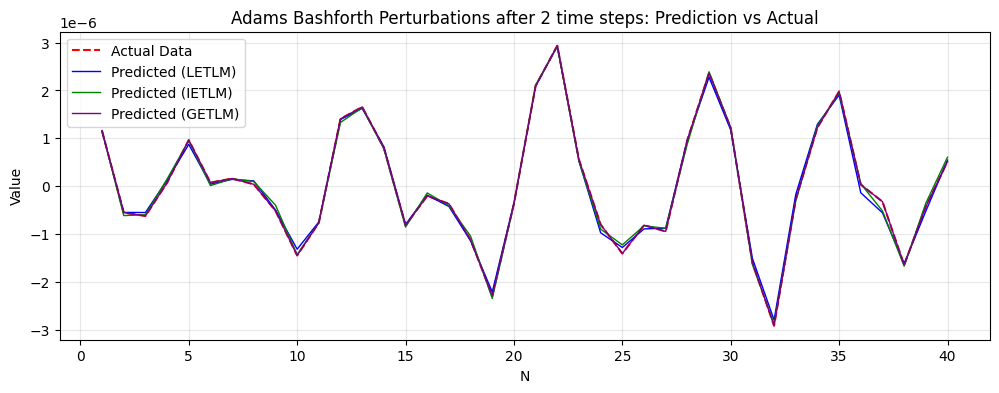

tensor(0.0027)
IETLM norm: tensor(0.0467)
LETLM norm: tensor(0.0523)
GETLM norm: tensor(2.3747e-07)


<Figure size 640x480 with 0 Axes>

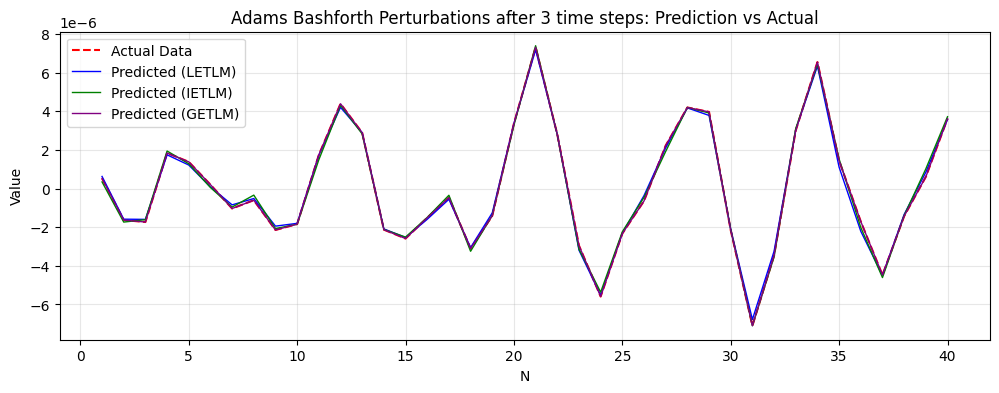

tensor(0.0023)
IETLM norm: tensor(0.0431)
LETLM norm: tensor(0.0480)
GETLM norm: tensor(5.6938e-07)


<Figure size 640x480 with 0 Axes>

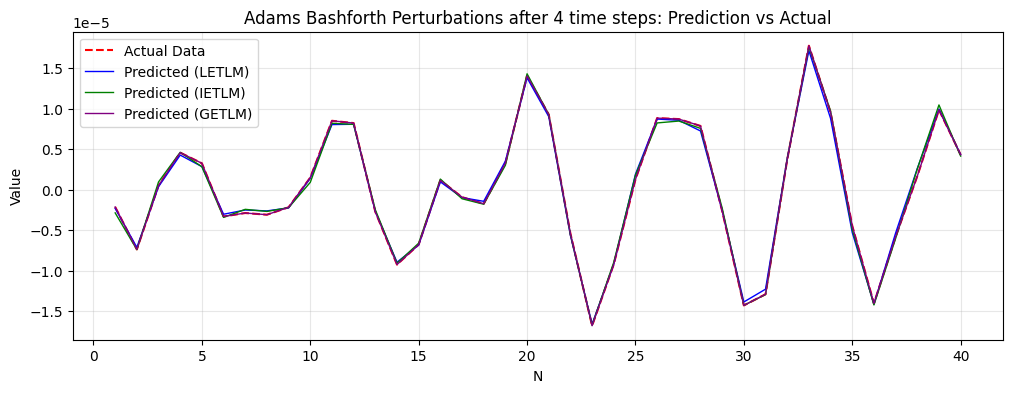

tensor(0.0021)
IETLM norm: tensor(0.0409)
LETLM norm: tensor(0.0455)
GETLM norm: tensor(1.3901e-06)


<Figure size 640x480 with 0 Axes>

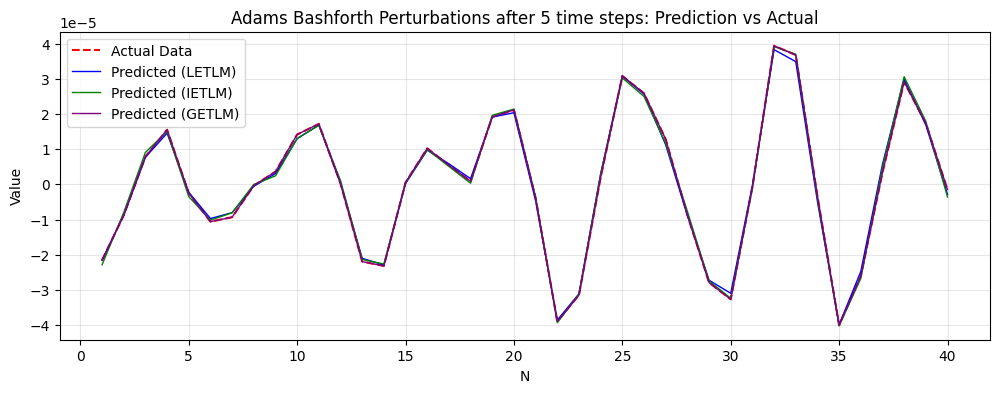

tensor(0.0020)
IETLM norm: tensor(0.0390)
LETLM norm: tensor(0.0443)
GETLM norm: tensor(3.5565e-06)


<Figure size 640x480 with 0 Axes>

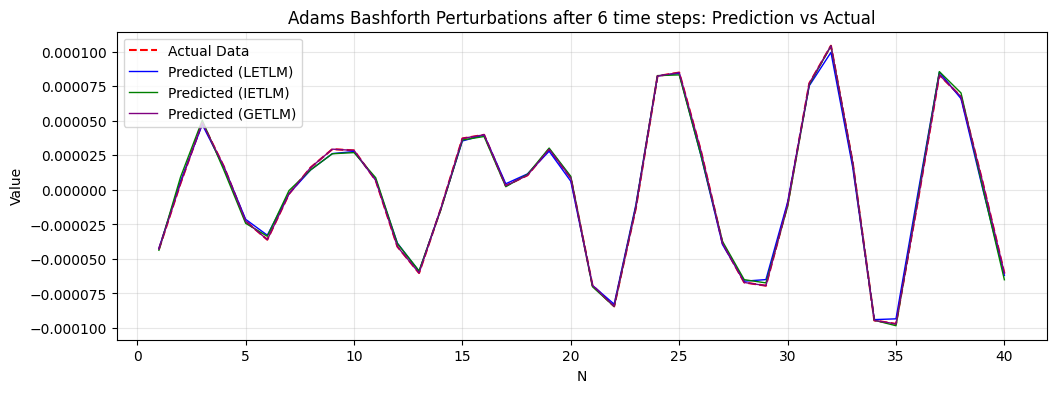

tensor(0.0019)
IETLM norm: tensor(0.0373)
LETLM norm: tensor(0.0436)
GETLM norm: tensor(9.5090e-06)


<Figure size 640x480 with 0 Axes>

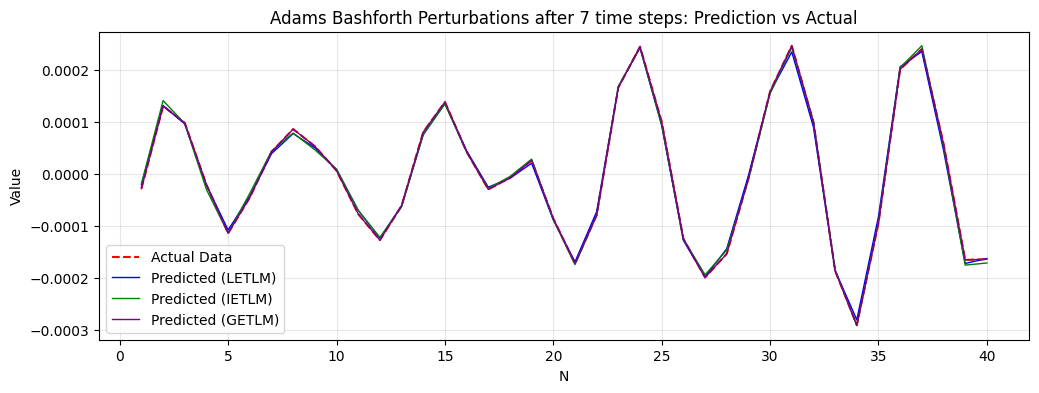

tensor(0.0019)
IETLM norm: tensor(0.0357)
LETLM norm: tensor(0.0432)
GETLM norm: tensor(2.4846e-05)


<Figure size 640x480 with 0 Axes>

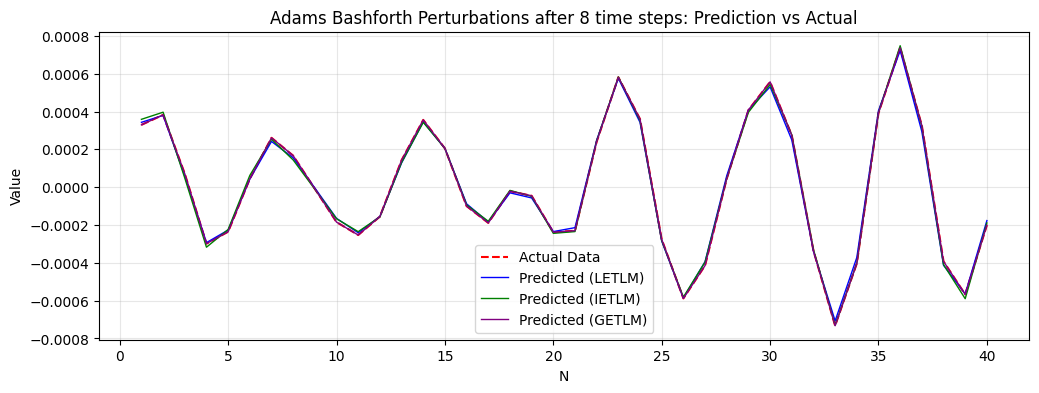

tensor(0.0019)
IETLM norm: tensor(0.0344)
LETLM norm: tensor(0.0430)
GETLM norm: tensor(6.4267e-05)


<Figure size 640x480 with 0 Axes>

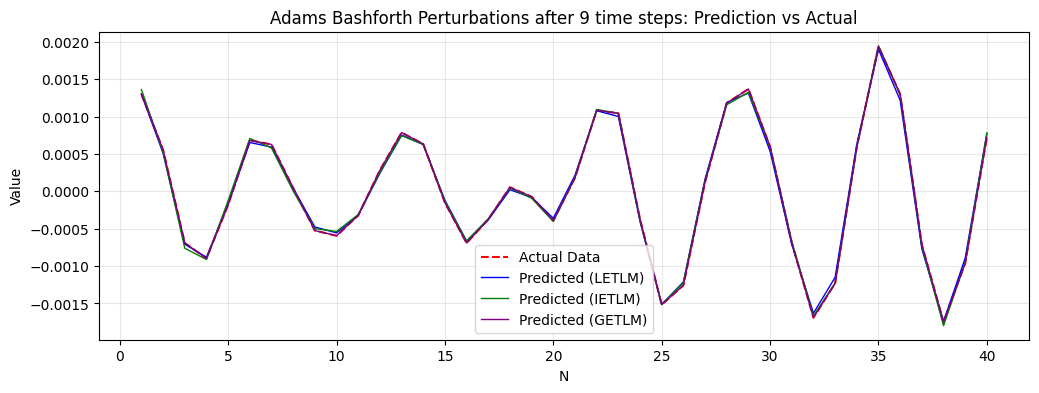

tensor(0.0018)
IETLM norm: tensor(0.0332)
LETLM norm: tensor(0.0430)
GETLM norm: tensor(0.0002)


<Figure size 640x480 with 0 Axes>

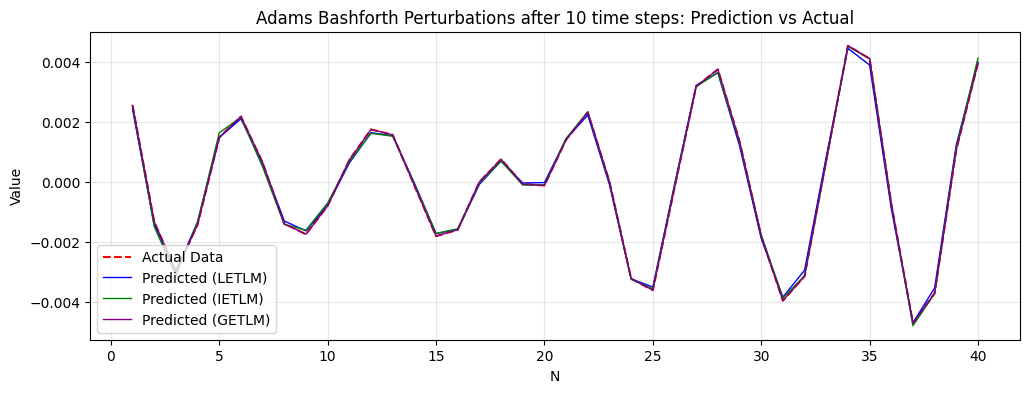

tensor(0.0019)
IETLM norm: tensor(0.0322)
LETLM norm: tensor(0.0430)
GETLM norm: tensor(0.0004)


<Figure size 640x480 with 0 Axes>

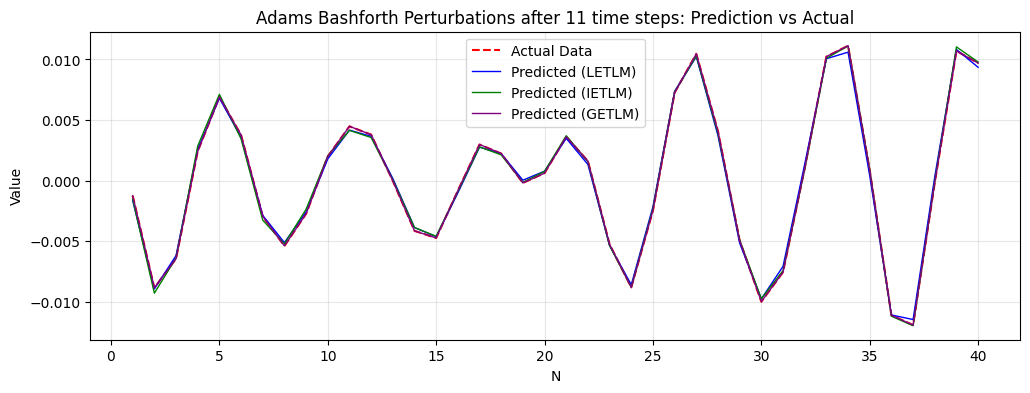

<Figure size 640x480 with 0 Axes>

In [89]:
# We will now compare the TLMS to the actual data to see 

# We first set a starting point for the TLMS
starting_time = 1

x_values = np.arange(1, N + 1)

LETLM_norm= []
IETLM_norm = []
GETLM_norm = []


LETLM_TT_result = []
IETLM_TT_result = []
GETLM_TT_result = []


# The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
test_0 = test_final_pert[1+starting_time]
LETLM_test = test_0
IETLM_test = test_0
GETLM_test_future = test_0
GETLM_test_current = test_final_pert[starting_time]

letlm_norm = L2_norm(LETLM_test, test_0)
ietlm_norm = L2_norm(IETLM_test, test_0)
getlm_norm = L2_norm(GETLM_test_future, test_0)



LETLM_norm.append(letlm_norm)
IETLM_norm.append(ietlm_norm)
GETLM_norm.append(getlm_norm)

index = 1+starting_time

LETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
IETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )

print(LETLM_TT)
LETLM_TT_result.append(LETLM_TT)
IETLM_TT_result.append(IETLM_TT)
GETLM_TT_result.append(GETLM_TT)





plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='blue', linewidth=2)
plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)
# plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

plt.title(f"Leapfrog ensemble at zero: Prediction vs Actual")
plt.xlabel("N")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop

# We will now go through the steps to see how each of the TLMS goes 
for i in range(len(test_final_pert)-3):
    index = i+2 + starting_time
    test = test_final_pert[i+2 + starting_time]
    letlm = LETLMS[i+starting_time]
    # print(len(letlm))
    LETLM_test = letlm @ LETLM_test

    letlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], LETLM_test)
    print(letlm_tt)
    LETLM_TT_result.append(letlm_tt)
    # LETLM_TT = torch.cat((LETLM_TT, letlm_tt), dim = 0)


    # Ploting the IETLM
    ietlm = IETLMS[i+starting_time]
    IETLM_test = ietlm @ IETLM_test


    ietlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], IETLM_test)
    IETLM_TT_result.append(ietlm_tt)


    # IETLM_TT = torch.cat((IETLM_TT, ietlm_tt), dim = 0)



    GETLM_test_past = GETLM_test_current
    GETLM_test_current = GETLM_test_future

    NL = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][1]
    NK = torch.pinverse(GETLMS[i+starting_time][0]) @ GETLMS[i+starting_time][2]
    GETLM_test_future = NL @ GETLM_test_current + NK @ GETLM_test_past

    getlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future)

    # GETLM_TT = torch.cat((GETLM_TT, getlm_tt), dim = 0)
    GETLM_TT_result.append(getlm_tt)




    

    # We now need to calculate the L2 norm

    letlm_norm = L2_norm(LETLM_test, test)
    ietlm_norm = L2_norm(IETLM_test, test)
    getlm_norm = L2_norm(GETLM_test_future, test)
    print('IETLM norm:', ietlm_norm)
    print('LETLM norm:', letlm_norm)
    print('GETLM norm:', getlm_norm)
    LETLM_norm.append(letlm_norm)
    IETLM_norm.append(ietlm_norm)
    GETLM_norm.append(getlm_norm)

    plt.figure(figsize=(12, 4))  # width=12 inches, height=4 inches
    plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
    plt.plot(x_values, LETLM_test.detach().cpu().numpy(), label='Predicted (LETLM)', color='blue', linewidth=1)
    plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    plt.plot(x_values, GETLM_test_future.detach().cpu().numpy(), label='Predicted (GETLM)', color='purple', linewidth=1)

    plt.title(f"Adams Bashforth Perturbations after {i+1} time steps: Prediction vs Actual")
    plt.xlabel("N")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show() # This creates a fresh window/plot for each step in the loop
    plt.clf()
    

    
    # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    # plt.show()
    # plt.clf()



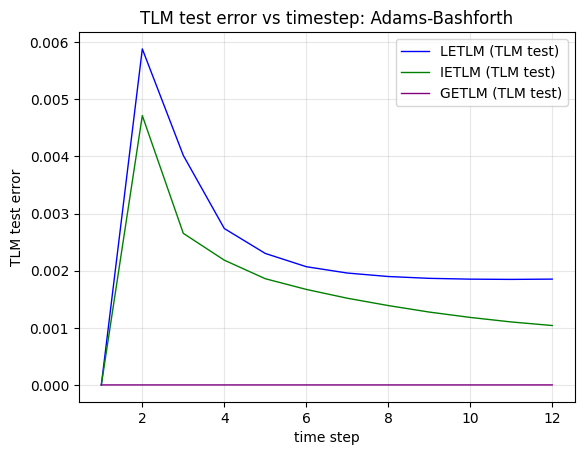

<Figure size 640x480 with 0 Axes>

In [90]:
x_values_norm = np.arange(1,len(IETLM_norm)+1)

plt.plot(x_values_norm, LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: Adams-Bashforth")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2839005231.py:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, LETLM_TT_result/IETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2839005231.py:6: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, IETLM_TT_result/IETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/2839005231.py:7: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, GETLM_TT_result/IETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)


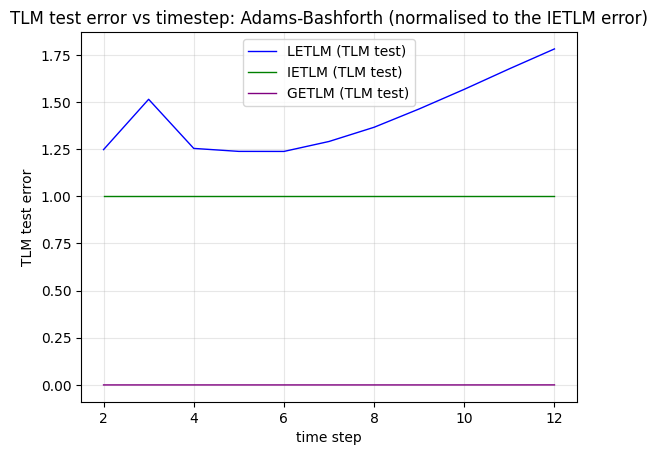

<Figure size 640x480 with 0 Axes>

In [91]:
LETLM_TT_result = np.array(LETLM_TT_result)
IETLM_TT_result = np.array(IETLM_TT_result)
GETLM_TT_result = np.array(GETLM_TT_result)

plt.plot(x_values_norm, LETLM_TT_result/IETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_TT_result/IETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_TT_result/IETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: Adams-Bashforth (normalised to the IETLM error)")
plt.xlabel("time step")
plt.ylabel("TLM test error")
# plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/717051106.py:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, LETLM_TT_result/LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/717051106.py:6: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, IETLM_TT_result/LETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_25354/717051106.py:7: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, GETLM_TT_result/LETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)


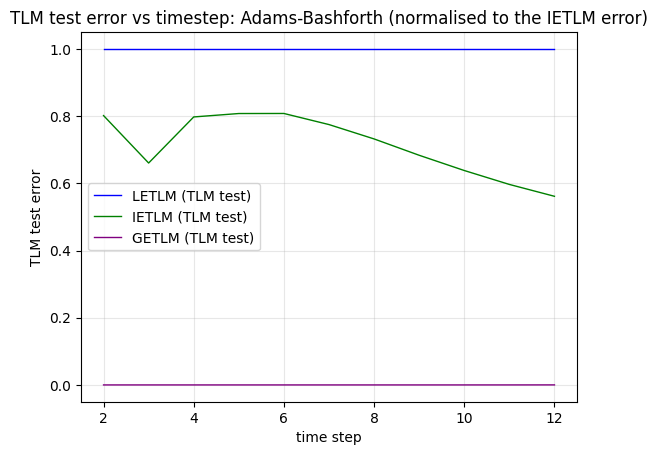

<Figure size 640x480 with 0 Axes>

In [92]:
LETLM_TT_result = np.array(LETLM_TT_result)
IETLM_TT_result = np.array(IETLM_TT_result)
GETLM_TT_result = np.array(GETLM_TT_result)

plt.plot(x_values_norm, LETLM_TT_result/LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values_norm, IETLM_TT_result/LETLM_TT_result, label='IETLM (TLM test)', color='green', linewidth=1)
plt.plot(x_values_norm, GETLM_TT_result/LETLM_TT_result, label='GETLM (TLM test)', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: Adams-Bashforth (normalised to the IETLM error)")
plt.xlabel("time step")
plt.ylabel("TLM test error")
# plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

In [93]:
print(GETLM_TT_result)



[0.00000000e+00 1.26236614e-15 9.64162958e-15 5.63913870e-14
 3.24196151e-13 1.93231837e-12 1.26488449e-11 9.04218378e-11
 6.17337748e-10 4.13025963e-09 2.54908495e-08 1.95558654e-07]
